# Rossi-$\alpha$ Methods Benchmark: the cost of precision

Estimators of the prompt decay constant $\alpha$ for a subcritical U235–H2O sphere with an
external B10 detector, compared on **accuracy** and, above all, on **how many histories (and how
much wall-clock time) each one needs to reach the same statistical precision** — across an
8-point $k_{eff}$ grid (0.40–0.98) and a detector-distance scan.

| method | observable | pair/single scaling |
|---|---|---|
| **Point kinetics (PK)** | $\alpha=(k(1-\beta_{eff})-1)/(k\Lambda)$, from one IFP eigenvalue run | model — no detector histories |
| **Doubles (parent-ID)** | same-chain detection-pair $\Delta t$, chains tagged by `parent_id` | pairs, rate $\propto\varepsilon^2$ — *unphysical best case* |
| **Doubles (realistic)** | all pairs + accidental background at the optimal source rate | pairs, no chain oracle — the honest competitor |
| **ACDC** | $\sum_i F_i\!\int g_i(t)g_i(t{+}\tau)\,dt$ from per-cell sweeps | singles per cell, rate $\propto\varepsilon$ |
| **Pulsed die-away** | singles envelope $s(t)\sim e^{\alpha t}$ | singles — but needs a *pulsable* source |

**One convergence metric for every method.** $\sigma_\alpha$ is the *across-realization* standard
deviation: partition a run into disjoint, equal-size realizations (sphere → disjoint `parent_id`
ranges; sweep → disjoint `parent_id` ranges per cell, assembled across cells), fit $\alpha$ in
each, take the spread. No $\kappa_S$ fudge, no Poisson approximation — identical for all methods.
Chain bootstrap and the MLE Fisher error are kept only as cross-checks. The target is
$\sigma_\alpha \le 5\%\,|\alpha_{ref}|$, with $\alpha_{ref}$ the common high-statistics
consensus value.

Three foundations carried over: **(1)** OpenMC under-disperses fission multiplicity
($E[n(n{-}1)]\approx2.06$ vs physical 4.63), so ACDC uses the calibrated $M_{sim}=2.76$; $\alpha$
is unaffected. **(2)** $\alpha$ is the *late-time* fundamental-mode slope — every method is fit in
the same frozen window per $k$. **(3)** The realistic Doubles fit needs a flat background; the raw
pulsed all-pairs fit silently degenerates into the singles die-away.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from project.analysis import greens_loader as gl
from project.analysis import rossi_benchmark as rb
# k=0.98 record-extension fix (2026-07-12): the 10 ms histogram record truncated the
# ACDC assembly's overlap integral near critical; every k=0.98 quantity below uses the
# 40 ms extended record + its plateau window via this additive module. See
# outputs/presentation/K098_EXTENSION_REPORT.md. All other k are byte-identical paths.
from project.analysis import k098_record_extension as kre
# k=0.98 flagship (2026-09): path-parameterised 40 ms analysis. Picks the bench100M
# campaign sweep + matched sphere when they are on disk and falls back to the
# bench10M 40 ms rebuild otherwise; §2c states which one it used.
from project.analysis import flagship_k098 as fk98
# PK-departure fix (2026-07-12): the §1 departure panel is measured against the
# band-median FUNDAMENTAL alpha (the §0b dashed line), not the window-fit alpha,
# whose frozen window still carries a few-% higher-mode tail at mid k. See
# outputs/presentation/PK_DEPARTURE_AUDIT.md.
from project.analysis import pk_departure as pkd

FIGURES_DIR = Path("../outputs/figures/benchmark")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS = rb.RESULTS_ROOT

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12, "legend.fontsize": 10,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.9, "lines.markersize": 6,
})

# 8-point k grid; original 4 also have 40M high-precision sweeps for the gate.
LABELS = ["098", "095", "090", "080", "070", "060", "050", "040"]
ANCHOR_LABELS = ["098", "090", "070", "040"]

# Method-centric style: color = method (not k) for every cost figure.
M = {
    "acdc":      dict(label="ACDC",                color="#1f77b4", marker="s"),
    "oracle":    dict(label="Doubles (parent-ID)", color="#d62728", marker="o"),
    "realistic": dict(label="Doubles (realistic)", color="#ff7f0e", marker="^"),
    "die":       dict(label="die-away*",           color="#2ca02c", marker="D"),
    "pk":        dict(label="point kinetics",      color="#7f7f7f", marker=None),
}
# per-k ramp kept only for the alignment-gate overlay
KCOL = {"098": "#08306b", "095": "#2171b5", "090": "#4292c6", "080": "#41ab5d",
        "070": "#ff7f0e", "060": "#e6550d", "050": "#d62728", "040": "#7a0177"}
MAXB = 500           # cap realizations/budget at 500: std-of-std ~ 1/sqrt(2*499) ~ 3%
                     # (very clean) while bounding runtime. At 100M the low-budget end
                     # could afford ~3300 blocks, but past a few hundred the std-of-std
                     # gain is marginal and the cost is real. The high-budget end keeps
                     # its few-block scatter, shown honestly by the error bars.
TARGET = 0.05        # sigma_alpha / |alpha| target


def fmt_N(n):
    if n is None or not np.isfinite(n):
        return "—"
    for u, s in [(1e12, "T"), (1e9, "G"), (1e6, "M"), (1e3, "k")]:
        if abs(n) >= u:
            return f"{n/u:.1f}{s}"
    return f"{n:.0f}"


def fmt_t(s):
    if not np.isfinite(s):
        return "—"
    if s < 120:
        return f"{s:.0f} s"
    if s < 7200:
        return f"{s/60:.0f} min"
    if s < 1.728e5:
        return f"{s/3600:.1f} h"
    return f"{s/86400:.1f} d"


REL_CAP = 0.5   # sigma/|alpha| ceiling: points above this are not measurements


def draw_master_curve(ax, curves, scaling, h2t, alpha_ref,
                      methods=("acdc", "oracle", "realistic", "die"), band=None):
    # Only MEASURING-regime points are drawn: non-censored (>=5 blocks, >=80%
    # convergent) AND sigma/|alpha| < REL_CAP. A censored or sigma/|alpha|~3 point is
    # not a measurement -- it only stretches the y-axis and hides the real content in a
    # thin band -- so the cell's printout lists the hidden budgets instead. Per method:
    #   filled markers +/- std-of-std = measured sigma(N);
    #   line through them             = the SINGLE fit_sigma_scaling slope (SOLID when
    #                                   ~ -1/2, dense-DASH when off the law = pre-asymptotic)
    #                                   -- same number printed and annotated, no second refit;
    #   dotted                        = N^-1/2 projection to 5% -- drawn ONLY where the fit
    #                                   is NOT already on the law within the data (off-law OR
    #                                   target past the last point). Where the solid fit sits
    #                                   on -1/2 and reaches 5% among the points it crosses the
    #                                   marker itself, so a dotted overlay is redundant/omitted.
    ys = [TARGET]
    any_solid = False
    for i, m in enumerate(methods):
        c = curves[m]; meta = M[m]; sl = scaling[m]; h = h2t[m]
        d = c[c["sigma"].notna() & (c["sigma"] > 0)
              & (c["sigma"] / abs(alpha_ref) < REL_CAP)]
        if not len(d):
            continue
        yv = (d["sigma"] / abs(alpha_ref)).to_numpy()
        ax.errorbar(d["n_prime"], yv, yerr=d["sigma_err"] / abs(alpha_ref),
                    fmt=meta["marker"], color=meta["color"], capsize=2, lw=0,
                    elinewidth=1.1, markersize=6, label=meta["label"], zorder=5)
        ys.extend(yv.tolist())
        # SOLID/dashed = the fit_sigma_scaling OLS line through exactly these points
        # (its slope is what the cell prints); solid at ~ -1/2, dense-dash if steeper.
        if np.isfinite(sl["slope"]) and np.isfinite(sl["intercept"]) and len(d) >= 2:
            Ns = np.logspace(np.log10(d["n_prime"].min()), np.log10(d["n_prime"].max()), 30)
            line = np.exp(sl["intercept"] + sl["slope"] * np.log(Ns)) / abs(alpha_ref)
            solid = abs(sl["slope"] + 0.5) < 0.15
            any_solid |= solid
            ax.plot(Ns, line, ls="-" if solid else (0, (5, 1)),
                    color=meta["color"], lw=1.7, zorder=4)
            xt = float(d["n_prime"].max())
            yt = np.exp(sl["intercept"] + sl["slope"] * np.log(xt)) / abs(alpha_ref)
            # stagger the annotation vertically by method index so they never collide
            # (14 pt spacing: > the 8 pt font even when two line ends nearly coincide)
            ax.annotate(f"{sl['slope']:+.2f}", (xt, yt), color=meta["color"], fontsize=8,
                        xytext=(5, (i - 1.5) * 14), textcoords="offset points", va="center")
        # dotted N^-1/2 projection to 5% -- ONLY when the fit is not already on the law
        # within the data (pre-asymptotic slope, whose own extrapolation is unreliable,
        # OR a target beyond the last measured point). On-law methods that reach 5% among
        # their points have the solid fit cross the marker directly -> no dotted overlay.
        if h["ok"] and np.isfinite(h["n_target"]):
            if (not sl["slope_ok"]) or h["extrapolated"]:
                Nd = np.logspace(np.log10(h["anchor_N"]), np.log10(h["n_target"]), 30)
                ax.plot(Nd, h["anchor_sigma"] / abs(alpha_ref) * np.sqrt(h["anchor_N"] / Nd),
                        ls=":", color=meta["color"], lw=1.4, alpha=0.7, zorder=3)
            ax.scatter([h["n_target"]], [TARGET], marker=meta["marker"], color=meta["color"],
                       s=130, zorder=6, edgecolor="k", linewidth=0.8)
        # BAND estimator overlay (rb.fit_intercept_band): translucent fixed -1/2 line
        # through every asymptotic + populated ladder point, drawn BEHIND the data over
        # the band's own budget range and dotted where it has to reach past the last
        # band point to the 5% crossing; the open ring is that crossing. Both
        # estimators are shown so the figure carries the same comparison as the table.
        b = (band or {}).get(m)
        if b is not None and b["ok"] and np.isfinite(b["n_target"]):
            def _bline(N, b=b):
                return np.exp(b["log_c"] + b["slope_fixed"] * np.log(N)) / abs(alpha_ref)
            Nb = np.logspace(np.log10(b["n_min"]), np.log10(b["n_max"]), 40)
            ax.plot(Nb, _bline(Nb), "-", lw=4.5, color=meta["color"], alpha=0.22, zorder=2)
            nt = b["n_target"]
            if not (b["n_min"] <= nt <= b["n_max"]):
                a_, z_ = (b["n_max"], nt) if nt > b["n_max"] else (nt, b["n_min"])
                Nd = np.logspace(np.log10(a_), np.log10(z_), 20)
                ax.plot(Nd, _bline(Nd), ":", lw=3.0, color=meta["color"], alpha=0.35, zorder=2)
            ax.scatter([nt], [TARGET], marker=meta["marker"], s=210, facecolor="none",
                       edgecolor=meta["color"], linewidth=2.0, zorder=7)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.axhline(TARGET, color="0.35", ls="--", lw=1.0)
    ax.text(0.015, TARGET * 1.15, "target 5%", color="0.35", fontsize=10,
            transform=ax.get_yaxis_transform())
    if len(ys) > 1:
        ax.set_ylim(min(ys) * 0.7, max(ys) * 1.5)
    ax.set_xlabel("total transport histories $N$ (fair: sweep = per-cell × $n_{cells}$)")
    ax.set_ylabel(r"$\sigma_\alpha / |\alpha|$")
    ttl = r"solid: on $-1/2$ law  ·  dashed: pre-asymptotic" if any_solid else ""
    if band:
        ttl += ("\n" if ttl else "") + r"filled marker: anchor $N\to5\%$  ·  open ring: band"
    ax.legend(loc="lower left", fontsize=9, framealpha=0.9, title=ttl or None)

## 0. Estimator alignment at full statistics (acceptance gate)

Before any cost comparison: the model-based ACDC curve and the direct **Doubles (parent-ID)**
pair histogram must describe the *same* $R(\tau)$ on an absolute scale (this is what fixes
$M_{sim}$). Overlay of $R_{ACDC}(\tau)$ and the Doubles same-chain pair rate for the four
high-precision (40M sweep) $k$ values, clipped to the signal band. Exception: the $k=0.98$
panel uses the matched bench10M pair on the **extended 40 ms record** — the 10 ms histogram
record truncated the assembled $R(\tau)$ at late lag (scale ratio read 1.04; on the untruncated
record it is ~1.01). See `K098_EXTENSION_REPORT.md`.

**What the 100M flagship records say about this gate (measured in §2c).** The four panels below are
the 10M-tier record, where this gate passes at every $k$. On the 100M campaigns the error bars
shrink by $\sqrt{10}$ and a residual appears at $k=0.98$ that the 10M data could not resolve:
the absolute scale is $0.9874\pm0.0040$ (matched fission map, $3.2\sigma$ from unity), the
shape ratio scale$/(M_{emp}/M_{sim})$ is $0.984\pm0.004$ ($3.9\sigma$ from 1), and the two decay
constants are $\alpha_{ACDC}=-360.9\pm1.7$ against $\alpha_{BF}=-369.2\pm1.2$, i.e. **3.9$\sigma$
apart**, with the assembled curve decaying ~2% too slowly. The *same-sign* residual on the
$k=0.90$ 100M flagship is only $0.7\sigma$ (shape ratio $0.9949\pm0.0072$) and $1.3\sigma$ on the
alpha pair, so this is a near-critical effect, not a global bias.

**That residual is now diagnosed** (`GATE_DIAGNOSTICS_REPORT.md`). With identical baseline handling
on both curves the alpha gap is $0.5\%$ ($2\sigma$): $1.7\%$ of the quoted $2.2\%$ was the two fits
choosing different flat baselines (the assembly's LSQ floats $A=-0.2\%$, the pair MLE freezes
$w_0=+1.2\%$, at a measured leverage of $-474$ s$^{-1}$ per unit floor fraction). The remaining
$1.5\%$ amplitude residual lives entirely in the in-record vs beyond-record split of the pair
weight ($55.09\%$ of the measured pairs fall at $\tau\le40$ ms against $55.95\%$ for the assembly),
while the union of the 80 cell runs reproduces the sphere run's pairs to $0.2\%$, and coarsening
the assembly grid on the 1M $20\times20$ sweep drives the shape ratio monotonically down (0.977,
0.973, 0.963, 0.949 for $20\times20$, $4\times5$, $2\times5$, $1\times1$). That makes it the
within-cell weighting error of the assembly grid (the pair source $\propto F\,G^2$ sits deeper in a
cell than the uniform cell average, and deeper birth points carry a larger delayed-branch share);
the zero-cost fix to test next is a fission-weighted in-cell source for the confined runs. Nothing
in the cost comparison below depends on any of it, because both methods are compared on their own
$\sigma_\alpha$ scaling, not on their agreement.

k098 (ext 40 ms, bench10M pair): window pairs= 88657  scale=1.009  M_emp=2.92+/-0.12  alpha BF=   -363.7+/-   4.5  ACDC=   -370.7+/-   0.4  (1.55 sigma)
k090: window pairs=   187  scale=0.925  M_emp=2.57+/-0.13  alpha BF=  -1353.7+/- 144.8  ACDC=  -1546.9+/-  10.2  (1.33 sigma)
k070: window pairs=    22  scale=1.072  M_emp=2.75+/-0.29  alpha BF=  -3662.7+/-1345.3  ACDC=  -5374.6+/-  98.3  (1.27 sigma)
k040: window pairs=     8  scale=0.723  M_emp=2.92+/-0.43  alpha BF=  -8839.7+/-4911.4  ACDC= -10551.2+/- 453.3  (0.35 sigma)


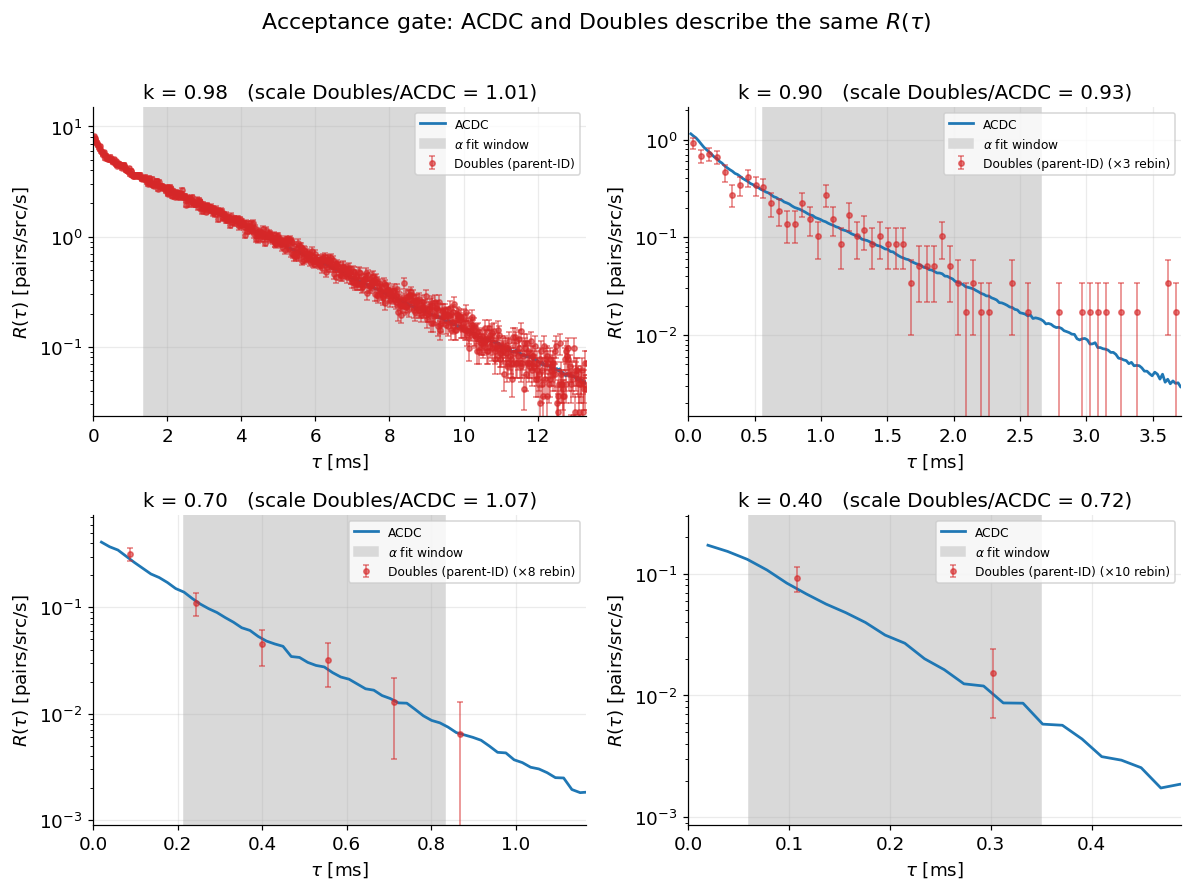

In [2]:
# k=0.98 gate on the extended 40 ms record (record-extension fix, see
# K098_EXTENSION_REPORT.md): same audited machinery, un-truncated assembly.
gate = {L: (kre.alignment_gate_ext(verbose=True) if L == "098"
            else rb.alignment_gate(L, verbose=True)) for L in ANCHOR_LABELS}

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, L in zip(axes.flat, ANCHOR_LABELS):
    r = gate[L]
    lo, hi = kre.ext_window() if L == "098" else rb.FIT_WINDOWS[L]
    # both R(tau) now span the full [0, 10 ms] range, so limit x to the data (the
    # window edge at worst) -- no dead axis/shading past the last point (was the
    # 5-14 ms empty band at k=0.98).
    xmax = min(1.4 * hi, float(r["tau"].max()))
    inwin = (r["tau"] >= 2 * rb.DT) & (r["tau"] <= xmax)
    ypos = r["R_acdc"][inwin]; ypos = ypos[ypos > 0]
    m = r["R_acdc"] > 0
    ax.semilogy(r["tau"][m] * 1e3, r["R_acdc"][m], "-", color=M["acdc"]["color"], lw=1.8,
                label="ACDC")
    # coarse-rebinned Doubles overlay + Poisson error bars: at low k the raw per-bin
    # pair count is 1-2 and the dots collapse onto quantization stripes.
    tb, Rb, eb = r["tau_bf_rebin"], r["R_bf_rebin"], r["R_bf_rebin_err"]
    nz = Rb > 0
    lbl = "Doubles (parent-ID)" + (f" (×{r['rebin']} rebin)" if r["rebin"] > 1 else "")
    ax.errorbar(tb[nz] * 1e3, Rb[nz], yerr=eb[nz], fmt="o", ms=3.5, color=M["oracle"]["color"],
                alpha=0.6, capsize=2, lw=0, elinewidth=1.0, label=lbl)
    ax.axvspan(lo * 1e3, hi * 1e3, color="0.85", zorder=0, label=r"$\alpha$ fit window")
    ax.set_xlim(0, xmax * 1e3); ax.set_ylim(ypos.min() * 0.5, ypos.max() * 2)
    ax.set_title(f"k = {int(L)/100:.2f}   (scale Doubles/ACDC = {r['scale_bf_over_acdc']:.2f})")
    ax.set_xlabel(r"$\tau$ [ms]"); ax.set_ylabel(r"$R(\tau)$ [pairs/src/s]")
    ax.legend(fontsize=8)
fig.suptitle("Acceptance gate: ACDC and Doubles describe the same $R(\\tau)$", y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "alignment_gate.png")
plt.show()

## 0b. Where the fit window comes from (the fundamental-mode plateau)

$\alpha$ is the **late-time (fundamental-mode) slope** of $R(\tau)$. $R(\tau)$ is multi-exponential:
at short lag the window still holds faster higher spatial modes, so the recovered $|\alpha|$ is
too large; as the window-start moves out, $|\alpha|$ falls and then **plateaus** once only the
fundamental mode survives, before the delayed/background tail flattens it again. The window is
**not hand-tuned** — `rb.plateau_window` derives it from the high-statistics ACDC $R(\tau)$: a
self-consistent band median fixes the fundamental decay constant, and the window start is the
*earliest* lag already on that plateau (best statistics). The mode-settling time is a property of
the geometry, so the **same window is shared by every method** (the fairness invariant). The
shaded band is the chosen $[\,$lo$,\,$hi$\,]$. Two distinct $\alpha$'s live in this figure and are
**not interchangeable** (`PK_DEPARTURE_AUDIT.md`): the dashed **band-median fundamental** — the
physics reference §1 measures the PK departure against — and the **in-window fit**, whose window
starts at the plateau-criterion *edge* and so still carries a few-% higher-mode tail at mid $k$
(at $k=0.90$: window-fit 1535 vs fundamental 1433). The window fit is the right quantity for the
*cost* benchmark (every method shares the same window — fairness); the fundamental is the right
one for the *physics* comparison against PK. The $k=0.98$ panel applies the same rule on the
**extended 40 ms record** (`K098_EXTENSION_REPORT.md`), where the plateau — and the window's upper
edge — is no longer ceilinged by the 10 ms record: window $[1.37,\,9.51]$ ms, fundamental
$\approx -368$.

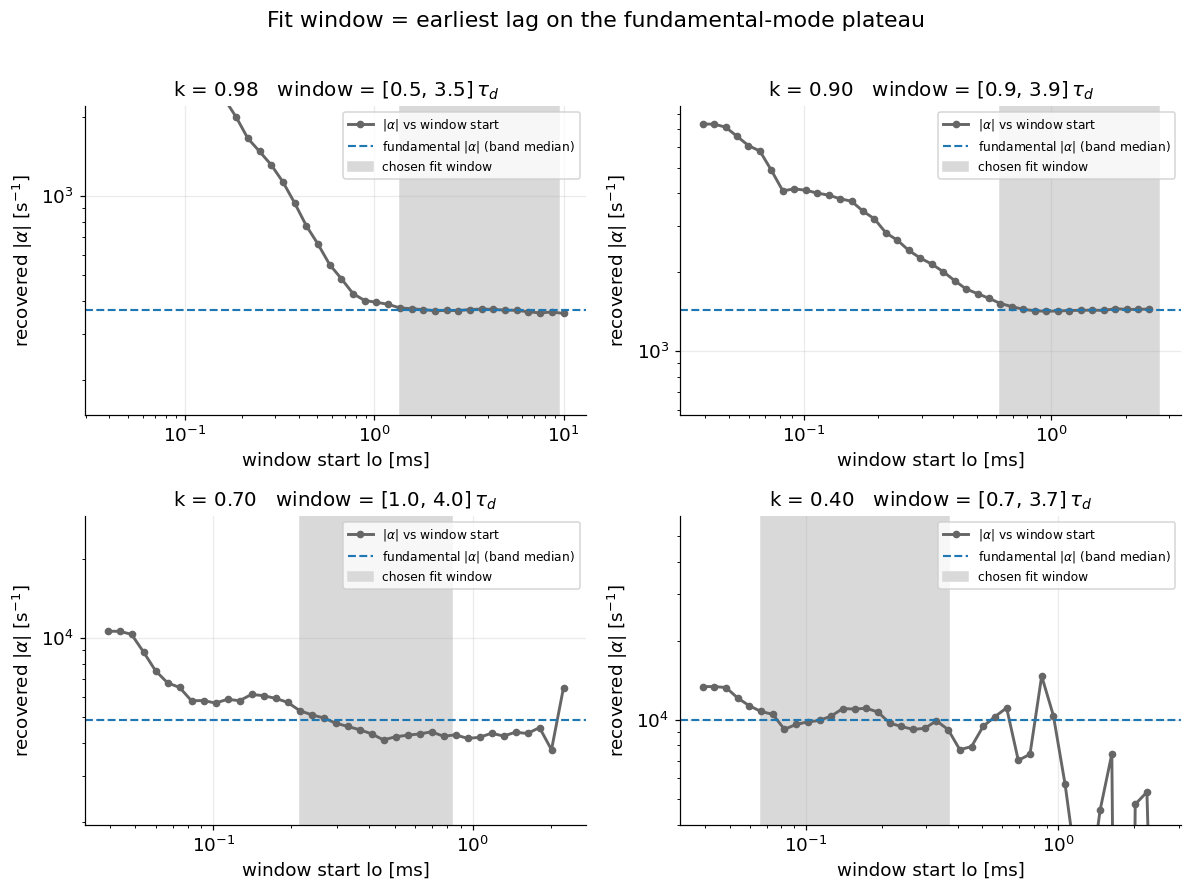

k=0.98: fundamental=   368 (-1% vs PK 372)   window-fit alpha=   371 (-0% vs PK)
k=0.90: fundamental=  1433 (+1% vs PK 1420)   window-fit alpha=  1506 (+6% vs PK)


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, L in zip(axes.flat, ANCHOR_LABELS):
    # k=0.98: plateau rule on the extended 40 ms record (K098_EXTENSION_REPORT.md)
    w = kre.derive_window(verbose=False) if L == "098" else rb.plateau_window(L)
    lo_g, a_g = w["lo_grid"], np.abs(w["alpha_grid"])
    af = abs(w["alpha_fund"])
    good = np.isfinite(a_g)
    ax.loglog(lo_g[good] * 1e3, a_g[good], "o-", color="0.4", ms=4, label=r"$|\alpha|$ vs window start")
    ax.axhline(af, color=M["acdc"]["color"], ls="--", lw=1.4, label=r"fundamental $|\alpha|$ (band median)")
    ax.axvspan(w["lo"] * 1e3, w["hi"] * 1e3, color="0.85", zorder=0, label="chosen fit window")
    # clip the y-axis to the physical band so fit-failure spikes at low k don't dominate
    ax.set_ylim(af * 0.4, af * 6)
    ax.set_title(f"k = {int(L)/100:.2f}   window = "
                 f"[{w['lo']/w['tau_decay']:.1f}, {w['hi']/w['tau_decay']:.1f}]"r"$\,\tau_d$")
    ax.set_xlabel(r"window start lo [ms]"); ax.set_ylabel(r"recovered $|\alpha|$ [s$^{-1}$]")
    ax.legend(fontsize=8, loc="upper right")
fig.suptitle(r"Fit window = earliest lag on the fundamental-mode plateau", y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fit_window_plateau.png")
plt.show()

# PK anchor (one-sided check): at k=0.98 PK is asymptotically exact, so the
# band-median FUNDAMENTAL must match it. PK is NOT used to choose windows at low k
# (it is known-wrong there -- that is the whole point of the k<0.9 departure panel
# below). On the extended record the k=0.98 fundamental lands on PK (the old -10%
# deficit was the 10 ms record truncation, K098_EXTENSION_REPORT.md). Both alphas are
# printed to keep them distinct (PK_DEPARTURE_AUDIT.md): the in-window FIT starts at
# the plateau-criterion edge, so at mid k it reads a few % above the fundamental
# (higher-mode tail) -- which is why the §1 departure panel uses the fundamental.
for L in ["098", "090"]:
    w = kre.derive_window(verbose=False) if L == "098" else rb.plateau_window(L)
    _, a_pk = rb._ifp_pk_alpha(L)
    apk = abs(a_pk.nominal_value)
    print(f"k={int(L)/100:.2f}: fundamental={abs(w['alpha_fund']):6.0f} "
          f"({100*(abs(w['alpha_fund'])-apk)/apk:+.0f}% vs PK {apk:.0f})   "
          f"window-fit alpha={abs(w['alpha']):6.0f} "
          f"({100*(abs(w['alpha'])-apk)/apk:+.0f}% vs PK)")

### 0c. The window is robust — and why it is NOT anchored on point kinetics

Because the window (§0b) is read off ACDC's $R(\tau)$, a fair objection is that it might bias the
comparison toward ACDC. It does not, and this figure is the proof.

**The window is a property of the system, not of ACDC.** The plateau scan at the flagship
$k{=}0.90$, computed *independently* from ACDC's $R(\tau)$ and from the **doubles'** $R(\tau)$: both
descend out of the fast higher-spatial-mode region and settle on the *same* fundamental plateau, so
the chosen window (shaded) is identical whichever estimator defines it. All the master-curve methods
are second-moment estimators of the *same* $R(\tau)$ — the window picks the same fundamental mode for
each.

**Why point kinetics cannot define the window.** The dotted line is PK/IFP, a point model: it omits
the spatial higher modes, so its $\alpha$ sits *below* the true measured fundamental — only
marginally at $k{=}0.90$ (visible here), but by ~10–15% at $k\le0.8$ (quantified in §1; the
previously quoted "up to 27%" was the window-fit departure, mostly higher-mode tail at the
practical window start — `PK_DEPARTURE_AUDIT.md`). "The
window that reproduces PK exactly" would therefore have to slide into the delayed-background tail —
where $|\alpha|$ bends down to meet the wrong PK value — biasing *every* method onto a number we
already know is incorrect. PK is a valid cross-check only as $k\to1$, where the spatial modes vanish.

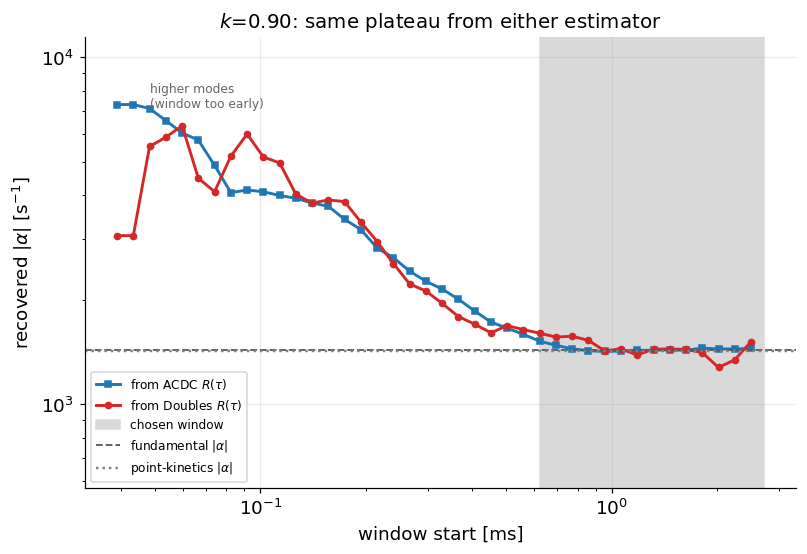

flagship k=0.90: fundamental from ACDC=1433, from doubles=1486, PK=1420  ->  window-invariant to the estimator; PK sits +1% off the fundamental here, more off-critical (§1)


In [4]:
FLp = rb.FLAGSHIP_LABEL
sweep = gl.load_sweep(FLp); Fp = rb.fission_coarse_sim(FLp, *sweep["G"].shape)
tau_ac, R_ac = rb.acdc_rossi(sweep, Fp, n_tau=rb.N_T - 1)
loA, aA = rb.plateau_scan(tau_ac, R_ac, n_scan=40)
dfp = rb.load_chain_events_from(rb.FLAGSHIP_DOUBLES_TRACK); nsp = int(dfp["parent_id"].max())
tau_bf, R_bf, _ = rb.bf_rossi(dfp, nsp, tau_max=rb.T_MAX, n_tau=rb.N_T - 1)
loB, aB = rb.plateau_scan(tau_bf, R_bf, n_scan=40)
w = rb.plateau_window(FLp); af = abs(w["alpha_fund"]); apk = abs(rb._ifp_pk_alpha(FLp)[1].nominal_value)

fig, axA = plt.subplots(figsize=(7.5, 5.2))
gA, gB = np.isfinite(aA), np.isfinite(aB)
axA.loglog(loA[gA] * 1e3, np.abs(aA[gA]), "s-", color=M["acdc"]["color"], ms=4, label=r"from ACDC $R(\tau)$")
axA.loglog(loB[gB] * 1e3, np.abs(aB[gB]), "o-", color=M["oracle"]["color"], ms=4, label=r"from Doubles $R(\tau)$")
axA.axvspan(w["lo"] * 1e3, w["hi"] * 1e3, color="0.85", zorder=0, label="chosen window")
axA.axhline(af, color="0.35", ls="--", lw=1.2, label=r"fundamental $|\alpha|$")
axA.axhline(apk, color=M["pk"]["color"], ls=":", lw=1.6, label=r"point-kinetics $|\alpha|$")
axA.set_ylim(af * 0.4, af * 8)
axA.text(loA[gA][2] * 1e3, af * 5, "higher modes\n(window too early)", fontsize=8, color="0.4")
axA.set_xlabel("window start [ms]"); axA.set_ylabel(r"recovered $|\alpha|$ [s$^{-1}$]")
axA.set_title(f"$k$={gl.K_OF_LABEL[FLp]:.2f}: same plateau from either estimator"); axA.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "window_provenance.png")
plt.show()
dep_fl = 100 * (af - apk) / apk   # flagship departure only; the k-dependence is §1's panel
print(f"flagship k=0.90: fundamental from ACDC={af:.0f}, from doubles={abs(rb._alpha_fund(loB, aB)):.0f}, "
      f"PK={apk:.0f}  ->  window-invariant to the estimator; PK sits {dep_fl:+.0f}% off the "
      f"fundamental here, more off-critical (§1)")

## 1. They agree where measurable — then the cost diverges

Context for everything below: at a uniform 1M-history budget, every method that *can* measure
returns the same $\alpha(k)$ (left); PK peels away below $k\approx0.9$ where the one-point model
loses the spatial physics (right). The departure is measured against the **band-median
fundamental** $|\alpha|$ of §0b — the physics quantity PK should reproduce — with honest errors
(Poisson bootstrap $\times\,\kappa_S$ statistical + band-read systematic): consistent with PK at
$k\ge0.90$, then **+10–15% for every $k\le0.81$** (peak $+15\pm8\%$ at $k=0.70$; even the most
conservative plateau read leaves PK $\ge6\%$ low across that whole range). The light series is
the same departure computed from the **practical window-fit** $\alpha$: the frozen §0b window
starts at the plateau-criterion *edge*, so its second-moment fit still carries a few-%
higher-mode tail at mid $k$ (at $k=0.90$: window-fit 1535 vs fundamental 1433 vs PK 1420), which
*overstated* the PK departure (up to +27%) — kept only to make that window systematic visible
(`PK_DEPARTURE_AUDIT.md`). The Doubles markers simply stop existing at low $k$ — that
absence is the result. The rest of the notebook quantifies the **cost** behind these markers.

**Source of the $k=0.98$ high-stats ACDC alpha.** It is read from whichever dataset §2c resolves
to (the 100M flagship record and its official $[1.5744, 9.7717]$ ms window when that campaign is on
disk, the bench10M 40 ms rebuild otherwise), through §2c's own plug-in estimator. The cell below
prints the value and the dataset it came from, so these breadth panels and the near-critical
section can no longer quote two different $k=0.98$ alphas (they did: $-370.7$ here against
$-360.9$ there).

k=0.98 high-stats ACDC alpha for the breadth panels: -360.94 +/- 1.66 s^-1   [source: bench100M flagship, 100,000,000-history sweep, window [1.5744, 9.7717] ms (as in §2c)]


/home/itay/miniforge3/envs/openmc-env/lib/python3.11/site-packages/scipy/optimize/_minpack_py.py:498: RuntimeWarning: overflow encountered in matmul
  cov_x = invR @ invR.T


/home/itay/miniforge3/envs/openmc-env/lib/python3.11/site-packages/scipy/optimize/_minpack_py.py:498: RuntimeWarning: overflow encountered in matmul
  cov_x = invR @ invR.T


/home/itay/miniforge3/envs/openmc-env/lib/python3.11/site-packages/scipy/optimize/_minpack_py.py:498: RuntimeWarning: overflow encountered in matmul
  cov_x = invR @ invR.T


/home/itay/miniforge3/envs/openmc-env/lib/python3.11/site-packages/scipy/optimize/_minpack_py.py:498: RuntimeWarning: overflow encountered in matmul
  cov_x = invR @ invR.T


...

/home/itay/miniforge3/envs/openmc-env/lib/python3.11/site-packages/scipy/optimize/_minpack_py.py:498: RuntimeWarning: overflow encountered in matmul
  cov_x = invR @ invR.T


/home/itay/miniforge3/envs/openmc-env/lib/python3.11/site-packages/scipy/optimize/_minpack_py.py:498: RuntimeWarning: overflow encountered in matmul
  cov_x = invR @ invR.T


/home/itay/miniforge3/envs/openmc-env/lib/python3.11/site-packages/scipy/optimize/_minpack_py.py:498: RuntimeWarning: overflow encountered in matmul
  cov_x = invR @ invR.T
/home/itay/miniforge3/envs/openmc-env/lib/python3.11/site-packages/scipy/optimize/_minpack_py.py:498: RuntimeWarning: overflow encountered in matmul
  cov_x = invR @ invR.T


/home/itay/miniforge3/envs/openmc-env/lib/python3.11/site-packages/scipy/optimize/_minpack_py.py:498: RuntimeWarning: overflow encountered in matmul
  cov_x = invR @ invR.T


/home/itay/miniforge3/envs/openmc-env/lib/python3.11/site-packages/scipy/optimize/_minpack_py.py:498: RuntimeWarning: overflow encountered in matmul
  cov_x = invR @ invR.T


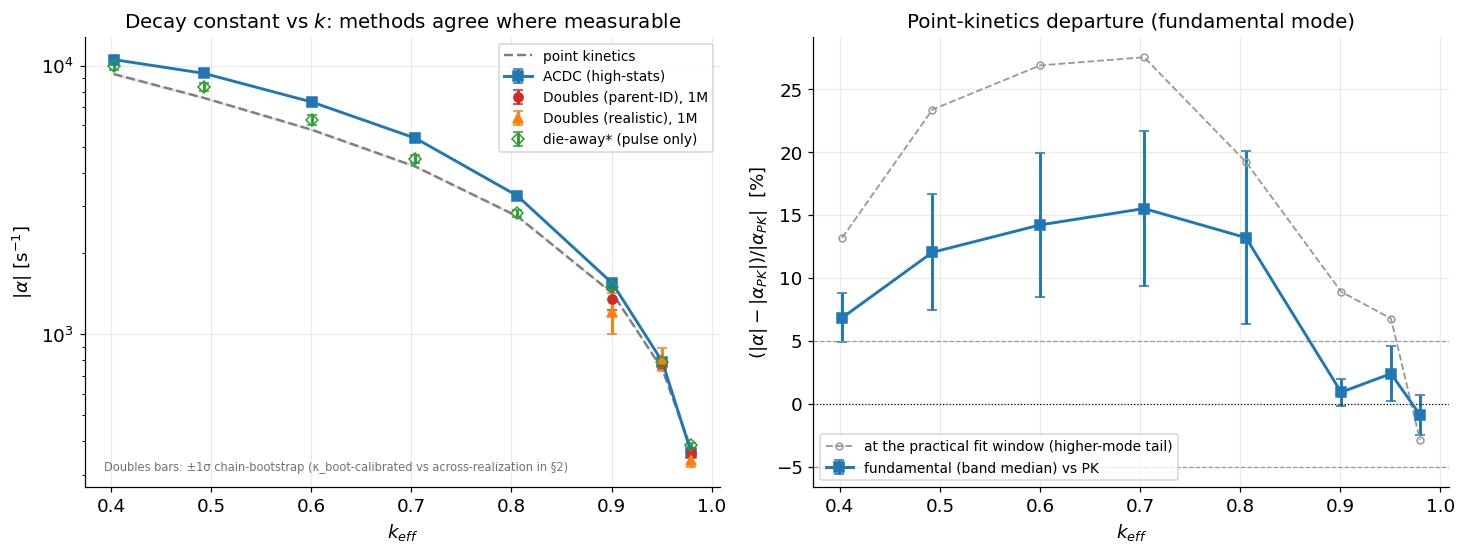

    k  alpha_PK  alpha_window_fit  alpha_fundamental  fund_err  dep_window_%  dep_fund_%  dep_fund_err_%
0.402    9321.0           10551.0             9959.0     159.0          13.2         6.8             2.0
0.493    7600.0            9377.0             8514.0     347.0          23.4        12.0             4.6
0.600    5780.0            7335.0             6602.0     326.0          26.9        14.2             5.7
0.704    4214.0            5375.0             4868.0     259.0          27.5        15.5             6.2
0.806    2753.0            3282.0             3116.0     188.0          19.2        13.2             6.8
0.901    1420.0            1547.0             1433.0      13.0           8.9         0.9             1.1
0.951     741.0             791.0              758.0      15.0           6.8         2.4             2.2
0.980     372.0             361.0              368.0       3.0          -2.9        -0.9             1.6

peak fundamental departure: +16% +/- 6% at k=0.70; PK 

In [5]:
# k=0.98 rows use the extended-record window / 40 ms assembly grid (record-extension
# fix, K098_EXTENSION_REPORT.md); every other label is the unchanged audited path.
bench = pd.DataFrame([(kre.benchmark_row_ext(n_boot=60, rng=20 + i) if L == "098"
                       else rb.benchmark_row(L, n_boot=60, rng=20 + i))
                      for i, L in enumerate(LABELS)])
bench = bench.sort_values("k").reset_index(drop=True)

# high-stats ACDC truth per k (for the PK-departure systematic). k=0.98 comes from
# whichever dataset §2c uses -- the SAME fk98.resolve_dataset selection -- so the
# breadth panels and the near-critical section quote one k=0.98 alpha. Before this
# (K098_100M_REPORT loose end) these panels read the bench10M extended-record
# consensus (-370.7) while §2c measured -360.9 on the 100M flagship.
acdc_best = {L: rb.acdc_alpha_sigma(L) for L in LABELS if L != "098"}
DS98_BREADTH = fk98.resolve_dataset("bench100M", "bench10M")
if DS98_BREADTH == "bench10M":
    acdc_best["098"] = kre.acdc_alpha_sigma_ext()
    A98_SOURCE = "bench10M extended 40 ms record (kre.acdc_alpha_sigma_ext)"
else:
    _i98 = fk98.inputs(DS98_BREADTH)
    _w98 = fk98.window(DS98_BREADTH)["window"]
    # fk98._acdc_plugin is exactly §2c's ACDC estimator (plug-in assembly on the
    # dataset's own grid, Poisson bootstrap x KAPPA_S), legacy F as there.
    _a98, _s98, _ = fk98._acdc_plugin(_i98, _i98["F_sim"], _w98, n_boot=100, rng=98)
    acdc_best["098"] = (float(_a98), float(_s98), int(_i98["n_sweep_total"]))
    A98_SOURCE = (f"{DS98_BREADTH} flagship, {_i98['n_sweep_total']:,}-history sweep, "
                  f"window [{_w98[0]*1e3:.4f}, {_w98[1]*1e3:.4f}] ms (as in §2c)")
print(f"k=0.98 high-stats ACDC alpha for the breadth panels: {acdc_best['098'][0]:.2f} "
      f"+/- {acdc_best['098'][1]:.2f} s^-1   [source: {A98_SOURCE}]")

bench["acdc_hi"] = [acdc_best[L][0] for L in bench["label"]]
bench["acdc_hi_err"] = [acdc_best[L][1] for L in bench["label"]]

# PK-departure fix (2026-07-12, PK_DEPARTURE_AUDIT.md): the physics claim "PK misses
# spatial modes" is measured against the band-median FUNDAMENTAL |alpha| (the §0b
# dashed line; pk_departure.alpha_fund_sigma = same audited scan machinery, sigma =
# Poisson-bootstrap x kappa_S stat (+) band-read systematic), NOT the window-fit
# acdc_hi above: the frozen windows start at the plateau-criterion edge, where the
# second-moment fit still carries a few-% higher-mode tail at mid k (k=0.90:
# window-fit 1535 vs fundamental 1433 vs PK 1420). Seeds match the audit table.
fund = {L: pkd.alpha_fund_sigma(L, n_boot=100, rng=100 + i) for i, L in enumerate(LABELS)}
bench["fund"] = [fund[L]["alpha_fund"] for L in bench["label"]]
bench["fund_err"] = [fund[L]["sigma_total"] for L in bench["label"]]
kk = bench["k"].to_numpy()

fig, (axA, axB) = plt.subplots(1, 2, figsize=(13.5, 5.2))
axA.plot(kk, np.abs(bench["pk"]), "--", color=M["pk"]["color"], lw=1.6, label=M["pk"]["label"])
axA.fill_between(kk, np.abs(bench["pk"]) - bench["pk_err"], np.abs(bench["pk"]) + bench["pk_err"],
                 color=M["pk"]["color"], alpha=0.12)
axA.errorbar(kk, np.abs(bench["acdc_hi"]), yerr=bench["acdc_hi_err"], fmt="s-",
             color=M["acdc"]["color"], capsize=3, label="ACDC (high-stats)")
ok_o = ~bench["bf_oracle_cens"]
axA.errorbar(kk[ok_o], np.abs(bench["bf_oracle"][ok_o]), yerr=bench["bf_oracle_err"][ok_o],
             fmt="o", color=M["oracle"]["color"], capsize=3, label="Doubles (parent-ID), 1M")
ok_r = ~bench["bf_real_cens"]
axA.errorbar(kk[ok_r], np.abs(bench["bf_real"][ok_r]), yerr=bench["bf_real_err"][ok_r],
             fmt="^", color=M["realistic"]["color"], capsize=3, label="Doubles (realistic), 1M")
axA.errorbar(kk, np.abs(bench["die"]), yerr=bench["die_err"], fmt="D", color=M["die"]["color"],
             mfc="none", capsize=3, label="die-away* (pulse only)")
axA.set_yscale("log"); axA.set_xlabel(r"$k_{eff}$"); axA.set_ylabel(r"$|\alpha|$ [s$^{-1}$]")
axA.set_title("Decay constant vs $k$: methods agree where measurable"); axA.legend(fontsize=9)
# the Doubles (parent-ID/realistic) 1M error bars are chain-bootstrap; the §2
# cross-check measures how it compares to the across-realization std (kappa_boot,
# calibrated out in the §3 costs).
axA.text(0.03, 0.03, "Doubles bars: ±1σ chain-bootstrap (κ_boot-calibrated vs across-realization in §2)",
         transform=axA.transAxes, fontsize=7.5, color="0.45", va="bottom")

# PK-departure fix (2026-07-12, PK_DEPARTURE_AUDIT.md): primary series = the
# fundamental-based departure (the physics claim); light open series = the same
# departure at the practical window fit, kept to make the window systematic visible.
# The old Doubles(parent-ID) series (another window-fit, noisier) moved out of this
# panel: estimator-vs-estimator agreement is the LEFT panel's story.
dep_f = (np.abs(bench["fund"]) - np.abs(bench["pk"])) / np.abs(bench["pk"])
dep_f_err = np.hypot(bench["fund_err"], np.abs(bench["fund"]) * bench["pk_err"]
                     / np.abs(bench["pk"])) / np.abs(bench["pk"])
dep_w = (np.abs(bench["acdc_hi"]) - np.abs(bench["pk"])) / np.abs(bench["pk"])
axB.errorbar(kk, 100 * dep_f, yerr=100 * dep_f_err, fmt="s-", color=M["acdc"]["color"],
             capsize=3, label="fundamental (band median) vs PK")
axB.plot(kk, 100 * dep_w, "o--", color="0.6", ms=4.5, mfc="none", lw=1.2,
         label="at the practical fit window (higher-mode tail)")
axB.axhline(0, color="k", lw=0.8, ls=":")
axB.axhline(5, color="0.6", lw=0.8, ls="--"); axB.axhline(-5, color="0.6", lw=0.8, ls="--")
axB.set_xlabel(r"$k_{eff}$"); axB.set_ylabel(r"$(|\alpha|-|\alpha_{PK}|)/|\alpha_{PK}|$  [%]")
axB.set_title("Point-kinetics departure (fundamental mode)"); axB.legend(fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "methods_vs_k.png")
plt.show()

# the audited numbers behind the right panel (PK_DEPARTURE_AUDIT.md task-1 table)
dtab = pd.DataFrame({
    "k": kk.round(3),
    "alpha_PK": np.abs(bench["pk"]).round(0),
    "alpha_window_fit": np.abs(bench["acdc_hi"]).round(0),
    "alpha_fundamental": np.abs(bench["fund"]).round(0),
    "fund_err": bench["fund_err"].round(0),
    "dep_window_%": (100 * dep_w).round(1),
    "dep_fund_%": (100 * dep_f).round(1),
    "dep_fund_err_%": (100 * dep_f_err).round(1),
})
print(dtab.to_string(index=False))
i_pk = int(np.argmax(dep_f.to_numpy()))
print(f"\npeak fundamental departure: {100*dep_f.iloc[i_pk]:+.0f}% +/- "
      f"{100*dep_f_err.iloc[i_pk]:.0f}% at k={kk[i_pk]:.2f}; PK consistent with the "
      f"fundamental at k>=0.90. The window-fit departure (light) peaks at "
      f"{100*dep_w.max():+.0f}% -- the excess over the fundamental series is the "
      f"higher-mode tail at the practical window start, not PK physics.")

### 1b. Why ACDC and die-away must agree — and where any residual gap comes from

ACDC and die-away both recover the *same* fundamental decay constant $\alpha$, so on the left
panel above they should land on top of each other. ACDC measures $\alpha$ from the **pair
correlation** $R(\tau)$ (a *second*-moment observable); die-away from the **singles arrival
envelope** (a *first*-moment observable). At a *finite* fit window the pair correlation carries
**more higher-spatial-mode contamination** than the singles envelope — so a too-early window makes
ACDC read a steeper (too-large $|\alpha|$) slope while die-away is already near the fundamental.
The proof that this is *window-driven*, not a bug or a real systematic, is that the two
**converge as the window moves late** (below). The principled plateau window (§0b) sits where the
gap is already small. This rules out the non-window suspects — delayed-background handling
(die-away fits a flat floor, ACDC carries the constant $A$), time binning (ACDC bins, die-away is
unbinned), and statistics (this is the 100M flagship): none of those would *converge* with window.

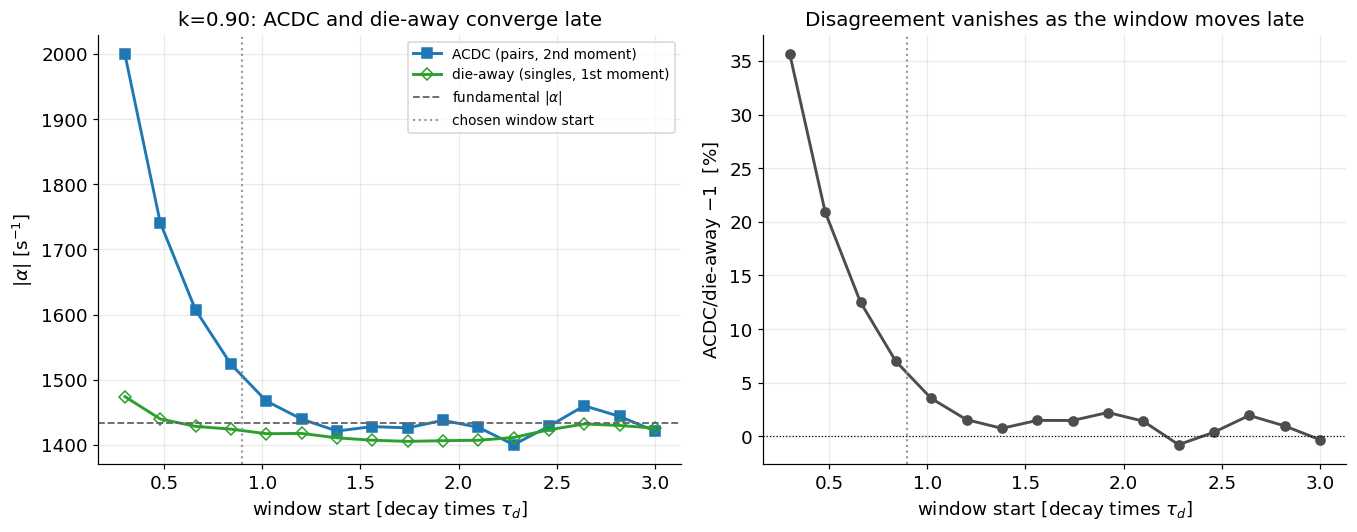

ACDC/die-away disagreement: +36% at 0.3 tau_d  ->  +7% at the chosen window (0.9 tau_d)  ->  -0% at 3.0 tau_d
VERDICT: window-driven higher-mode contamination (2nd moment > 1st moment), not a bug.


In [6]:
sc = rb.acdc_vs_dieaway_scan(rb.FLAGSHIP_LABEL, track_path=rb.FLAGSHIP_DOUBLES_TRACK)
s, a_ac, a_di = sc["s_grid"], np.abs(sc["alpha_acdc"]), np.abs(sc["alpha_die"])
w = rb.plateau_window(rb.FLAGSHIP_LABEL)
start_td = w["lo"] / w["tau_decay"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 5))
ax1.plot(s, a_ac, "s-", color=M["acdc"]["color"], label="ACDC (pairs, 2nd moment)")
ax1.plot(s, a_di, "D-", color=M["die"]["color"], mfc="none", label="die-away (singles, 1st moment)")
ax1.axhline(abs(sc["alpha_fund"]), color="0.4", ls="--", lw=1.2, label="fundamental $|\\alpha|$")
ax1.axvline(start_td, color="0.6", ls=":", lw=1.4, label="chosen window start")
ax1.set_xlabel(r"window start [decay times $\tau_d$]"); ax1.set_ylabel(r"$|\alpha|$ [s$^{-1}$]")
ax1.set_title(f"k={gl.K_OF_LABEL[rb.FLAGSHIP_LABEL]:.2f}: ACDC and die-away converge late")
ax1.legend(fontsize=9)

ratio = a_ac / a_di
ax2.plot(s, 100 * (ratio - 1), "o-", color="0.3")
ax2.axhline(0, color="k", lw=0.8, ls=":")
ax2.axvline(start_td, color="0.6", ls=":", lw=1.4)
ax2.set_xlabel(r"window start [decay times $\tau_d$]")
ax2.set_ylabel(r"ACDC/die-away $-1$  [%]")
ax2.set_title("Disagreement vanishes as the window moves late")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "acdc_vs_dieaway.png")
plt.show()

import numpy as _np
i = int(_np.argmin(_np.abs(s - start_td)))
print(f"ACDC/die-away disagreement: {100*(ratio[0]-1):+.0f}% at {s[0]:.1f} tau_d  ->  "
      f"{100*(ratio[i]-1):+.0f}% at the chosen window ({start_td:.1f} tau_d)  ->  "
      f"{100*(ratio[-1]-1):+.0f}% at {s[-1]:.1f} tau_d")
print("VERDICT: window-driven higher-mode contamination (2nd moment > 1st moment), not a bug.")

## 2. The master curve — $\sigma_\alpha$ vs total histories (flagship $k=0.90$)

The headline. A matched **100M-history** sphere run (Doubles) and per-cell sweep (ACDC, total =
per-cell × $n_{cells}$, so the budgets are *fair*) at $k=0.90$, gap 10 cm. For each method we
measure $\sigma_\alpha$ at a ladder of budgets from **disjoint** realizations of the flagship
run. Splitting one analog run into disjoint blocks is statistically equivalent to independent
re-runs — the histories are i.i.d., analog transport shares no state, and each particle rides an
independent RNG substream — and it is *cleaner* than re-running with a fixed seed (which would be
identical). So $\sigma_\alpha(N)=\mathrm{std}$ of $\alpha$ across blocks of size $N$ is the
honest across-realization uncertainty — the naive "repeat many times and take the std", but using
*every* disjoint block the data affords (up to a 500-block cap per budget), not an arbitrary
handful.

**Why each point has an error bar.** A standard deviation estimated from $B$ blocks carries its
own sampling error $\approx\sigma/\sqrt{2(B-1)}$. The low-budget end has *hundreds* of blocks
(bar $\sim$few %); the high-budget end has only a handful (bar grows). That is the entire reason
the old curve looked "noisy" — it was a real std-of-std, now shown.

**Only measurements are plotted.** A budget is shown for a method only where it *measured*:
non-censored (≥5 blocks and ≥80% of them reaching the 50-pair floor — the gate that removes the
old survivor-bias points) and $\sigma_\alpha/|\alpha|<0.5$. Budgets where the method could not
measure are listed in the printout below, not drawn as off-scale junk that squeezes the real
content into a thin band.

**Every block fit freezes its background weight.** The Doubles and die-away fits carry a real
flat floor (delayed-branch pairs for the parent-ID doubles, accidentals for the realistic
doubles, the delayed pedestal for die-away). That floor fraction is a property of the *system and
window*, not of the block — floor and signal counts both scale with budget — so refloating it in
every few-hundred-pair block is ill-conditioned: the barely-identified weight leaks its variance
into $\alpha$ and splices two different estimators into one $\sigma(N)$ curve (the old curve's
kink and nonsense slope). Instead $w_0$ is **frozen**: for parent-ID doubles and die-away from one
full-dataset fit where it is well identified (printed below); for the realistic doubles from each
block's own *observables* — measured singles count and duration → expected accidental pairs —
exactly how a real Rossi-$\alpha$ analysis pins its accidental floor. The residual uncertainty of
$w_0$ is a common systematic on $\alpha$'s value, not part of the per-realization spread.

**One line per method, honest about what it is.** The line is the single `fit_sigma_scaling` OLS
through exactly the plotted points — *the same slope the cell prints and annotates* (no second,
differently-filtered refit). Monte-Carlo gives $\sigma\propto N^{-1/2}$ asymptotically: a slope
near $-1/2$ is drawn **solid** (the method sits on the asymptotic line), a departing slope is
drawn **dense-dashed** (still pre-asymptotic); the printed values below the figure are the
measurement. A method already **on** the $-1/2$ law reaches 5% along its own solid line, so its
target marker sits directly on that line — no extra construction. The **dotted** projection is
therefore drawn for **only** the pre-asymptotic method(s) (here the realistic Doubles), whose own
shallow slope is unreliable to extrapolate: it slides the highest-$N$ *reliable* ($\ge6$-block)
anchor down the exact $N^{-1/2}$ CLT law for i.i.d. history blocks to the 5% target (low-$N$
$\sigma$ is biased high, so we never anchor there). That anchored law — not the method's own
free slope — fixes its histories-to-target number, and is the same $N^{-1/2}$ law the breadth and
cost-vs-$k$ panels (§3) use, so every method's cost is quoted on one consistent basis.

**The headline histories-to-5% is now a BAND fit, not a single anchor point**
(2026-09, `COST_ESTIMATOR_REPORT.md`). `histories_to_target` reads the intercept off exactly one
ladder point, the highest budget with at least 6 convergent blocks, and here that point has only
10 blocks, whose standard deviation carries a 24% sampling error of its own; since
$N\propto\sigma_0^2$ that is $\pm47\%$ on every quoted cost. `rb.fit_intercept_band` instead does a
weighted **fixed $-1/2$** fit through *every* ladder point that is asymptotic
($\sigma\le0.25|\alpha_{ref}|$) and populated ($\ge20$ blocks), and when both estimators are re-run
on 10 disjoint sub-datasets the band reproduces itself 3 to 8 times better than the anchor on every
method at both $k$, which is why the table below quotes the band and keeps the anchor beside it as
a comparison column. Because the statistical error fell roughly 15 times, two systematics now
dominate and are quoted rather than hidden: the `rel_cap` choice (measured in the cell below by
refitting the band over `rel_cap` $\in\{0.15,0.25,0.35\}$) and the placement of the frozen fit
window, which moves ACDC by $\pm6\%$ per §7 of the report for a one-lag shift. ACDC's quoted
$\pm11\%$ is 3% statistical $\oplus$ 9% `rel_cap` $\oplus$ 6% window. The incumbent
`histories_to_target`, `fit_sigma_scaling` and `FIT_WINDOWS` are untouched and still run.

* Read **horizontally** at the 5% line → histories each method needs.
* Read **vertically** at any budget → precision at equal cost.
* The **horizontal gap** between two curves → "X times more histories" (the paper's eq. 59 vs 60
  efficiency ratio — made explicit in §2b).

In [7]:
FL = rb.FLAGSHIP_LABEL
win = rb.FIT_WINDOWS[FL]

# matched 100M flagship data
df10 = rb.load_chain_events_from(rb.FLAGSHIP_DOUBLES_TRACK)          # sphere doubles events
n_sphere = int(df10["parent_id"].max())
events10, n_cell10 = rb.load_sweep_events(rb.FLAGSHIP_SWEEP_EVENTS)  # per-cell sweep events
n_cells = len(events10)
n_sweep_total = n_cell10 * n_cells
# F10 is the GLOBAL (full-flagship) fission map, reused by every ACDC block. The
# fission tally is not keyed by detection-event parent_id, so it cannot be split
# per block; reusing it removes F's own (tiny, high-statistics) sampling noise from
# the block scatter -- a deliberate, negligible variance suppression on ACDC's bar.
F10 = rb.fission_coarse_from_dir(rb.FLAGSHIP_DOUBLES_DIR, 8, 10)
# ONE |alpha_ref| everywhere it is needed (§1, §2, §3): the high-stats ACDC consensus
# per k. The event-level flagship-sweep alpha and the plateau fundamental differ from
# it by a few % (window/estimator systematic, not a real disagreement); printed once
# here so the single choice of denominator is explicit.
alpha_ref = acdc_best[FL][0]
print(f"|alpha_ref| = {abs(alpha_ref):.0f} (high-stats ACDC consensus); cf. "
      f"flagship-events {abs(rb.reference_alpha(FL, rb.FLAGSHIP_SWEEP_EVENTS)):.0f}, "
      f"plateau fundamental {abs(rb.plateau_window(FL)['alpha_fund']):.0f}")

bud_sp = rb.budget_ladder(n_sphere)
bud_sw = rb.budget_ladder(n_sweep_total)
print(f"flagship k={gl.K_OF_LABEL[FL]:.2f}: sphere {n_sphere:,} histories, "
      f"sweep {n_sweep_total:,} ({n_cell10:,}/cell x {n_cells})")

# Frozen background weights, ONE flat fit each at full-flagship statistics (the
# realistic method instead pins its accidental floor per block from observables).
# Refloating w in every few-hundred-pair block is ill-conditioned and splices two
# estimators into one sigma(N) curve -- see fit_alpha_mle's 'auto' caveat.
w0_oracle = rb.flat_background_weight(
    rb.same_parent_pair_dts(df10["time"].to_numpy(), df10["parent_id"].to_numpy(), win[1]),
    *win)
w0_die = rb.flat_background_weight(df10["time"].to_numpy(), *win)
print(f"frozen background weights: oracle w0={w0_oracle:.3f} (delayed-branch floor), "
      f"die-away w0={w0_die:.3f} (delayed pedestal)")

curves = {}
curves["oracle"] = rb.sigma_vs_budget(
    lambda n: rb.oracle_block_alphas(df10, n, n_sphere, win, max_blocks=MAXB,
                                     w_fixed=w0_oracle), bud_sp, n_sphere)
curves["realistic"] = rb.sigma_vs_budget(
    lambda n: rb.realistic_block_alphas(df10, n, n_sphere, win, rng=1, max_blocks=MAXB),
    bud_sp, n_sphere)
curves["die"] = rb.sigma_vs_budget(
    lambda n: rb.die_block_alphas(df10, n, n_sphere, win, max_blocks=MAXB,
                                  w_fixed=w0_die), bud_sp, n_sphere)
curves["acdc"] = rb.sigma_vs_budget(
    lambda n: rb.acdc_block_alphas(events10, F10, n, n_cell10, win, n_cells=n_cells, max_blocks=MAXB),
    bud_sw, n_sweep_total)

# The measuring-regime fit_sigma_scaling slope is BOTH printed here and drawn as the
# solid/dashed line (one number, no second refit). ~ -0.5 validates the 1/sqrt(N) law;
# a departing slope is flagged by the dashed style. The DOTTED target extrapolation
# uses fixed -1/2 from the >=6-block anchor.
scaling = {m: rb.fit_sigma_scaling(c, alpha_ref) for m, c in curves.items()}
h2t = {m: rb.histories_to_target(curves[m], alpha_ref, TARGET, scaling[m]) for m in curves}
for m in curves:
    cz = curves[m]
    nb = cz.loc[cz["sigma"].notna(), "n_convergent"]
    print(f"{M[m]['label']:22s} slope={scaling[m]['slope']:+.2f} "
          f"(ok={scaling[m]['slope_ok']})  blocks/pt={nb.min() if len(nb) else 0}-{nb.max() if len(nb) else 0}"
          f"  N->5%={fmt_N(h2t[m]['n_target'])}")
# hidden on the master curve = censored (pair-starved) OR non-measuring (sigma/|a|>=cap)
for m in curves:
    c = curves[m]
    hidden = c[c["sigma"].isna() | (c["sigma"] / abs(alpha_ref) >= REL_CAP)]["n_prime"].tolist()
    if hidden:
        print(f"  {M[m]['label']}: hidden (censored or sigma/|a|>={REL_CAP:g}) at N = "
              + ", ".join(fmt_N(n) for n in hidden))

|alpha_ref| = 1547 (high-stats ACDC consensus); cf. flagship-events 1567, plateau fundamental 1433
flagship k=0.90: sphere 99,999,407 histories, sweep 100,000,000 (1,250,000/cell x 80)


frozen background weights: oracle w0=0.054 (delayed-branch floor), die-away w0=0.006 (delayed pedestal)


Doubles (parent-ID)    slope=-0.40 (ok=True)  blocks/pt=5-185  N->5%=7.0M
Doubles (realistic)    slope=-0.34 (ok=False)  blocks/pt=5-185  N->5%=27.9M
die-away*              slope=-0.50 (ok=True)  blocks/pt=5-500  N->5%=263.4k
ACDC                   slope=-0.53 (ok=True)  blocks/pt=5-500  N->5%=1.6M
  Doubles (parent-ID): hidden (censored or sigma/|a|>=0.5) at N = 30.0k, 61.8k, 127.2k, 262.1k, 539.7k
  Doubles (realistic): hidden (censored or sigma/|a|>=0.5) at N = 30.0k, 61.8k, 127.2k, 262.1k, 539.7k
  die-away*: hidden (censored or sigma/|a|>=0.5) at N = 30.0k
  ACDC: hidden (censored or sigma/|a|>=0.5) at N = 30.0k


In [8]:
# ============ BAND intercept estimator + its split-sample error bar ==============
# Same curves as above; only the reduction changes. rb.fit_intercept_band is a
# weighted fixed -1/2 fit through every ladder point that is asymptotic
# (sigma <= rb.BAND_REL_CAP*|alpha_ref|) and populated (>= rb.BAND_MIN_BLOCKS blocks);
# h2t above slides ONE anchor point. Both are kept so the table can compare them.
band = {m: rb.fit_intercept_band(curves[m], alpha_ref, TARGET) for m in curves}

# The honest error bar: re-run the WHOLE estimator on DISJOINT sub-datasets (disjoint
# parent-id ranges of the sphere record, disjoint per-cell ranges of the sweep, each
# relabelled to 1..n so the audited block machinery applies unchanged). Splits are
# independent by construction, so their scatter is a real uncertainty; se_full =
# std/sqrt(n_splits) transfers it to the full-data estimate under sqrt(N) consistency.
# ACDC and die-away support 10 x 10M splits; at 10M the two Doubles ladders are
# censored below ~0.5M and do not leave >= 3 band points in every split, so they are
# quoted at the coarser 4 x 25M (their split SEs are the weakest numbers here).
cost_inputs_fl = {"label": FL, "fit_window": win, "df": df10, "n_sphere": n_sphere,
                  "events": events10, "n_cell": n_cell10, "n_cells": n_cells,
                  "n_sweep_total": n_sweep_total, "F": F10,
                  "alpha_ref": float(alpha_ref), "maxb": MAXB,
                  "w0_oracle": w0_oracle, "w0_die": w0_die}
SPLIT_N = {"acdc": 10, "die": 10, "oracle": 4, "realistic": 4}
full_fl = {f"n_target_{m}": band[m]["n_target"] for m in curves}
full_fl.update({f"anchor_{m}": h2t[m]["n_target"] for m in curves})
for m in ["oracle", "realistic", "die"]:
    full_fl[f"ratio_{m}_acdc"] = band[m]["n_target"] / band["acdc"]["n_target"]
splits_fl, summ_fl = {}, {}
for ns in sorted(set(SPLIT_N.values()), reverse=True):
    splits_fl[ns] = rb.split_sample_costs(cost_inputs_fl, ns, verbose=False)
    summ_fl[ns] = rb.split_cost_summary(splits_fl[ns], ns, full_fl).set_index("quantity")

# rel_cap systematic: refit the band on the SAME cached curves over the report's grid.
# Free (closed-form on <= 10 rows). Quoted as the half-spread about the grid midpoint.
# min_blocks is inert (moves N by < 0.9 split-SE everywhere) and stays frozen at 20.
REL_CAPS = (0.15, 0.25, 0.35)
WINDOW_SYST = {"acdc": 0.06}   # one-lag shift of the frozen window, report §7


def relcap_syst(cs, m, a_ref):
    v = np.array([rb.fit_intercept_band(cs[m], a_ref, TARGET, rel_cap=rc)["n_target"]
                  for rc in REL_CAPS])
    v = v[np.isfinite(v)]
    return (v.max() - v.min()) / 2 / np.median(v) if len(v) > 1 else np.nan


# convergent realizations at the budget the single-anchor rule anchored on
def anchor_blocks(cs, m, anch):
    a = anch[m]
    if not a["ok"] or not np.isfinite(a["anchor_N"]):
        return np.nan
    sel = cs[m]["n_prime"] == a["anchor_N"]
    return float(cs[m].loc[sel, "n_convergent"].iloc[0]) if sel.any() else np.nan


# a std from B blocks has SE(sigma)/sigma = 1/sqrt(2(B-1)); N ~ sigma^2 doubles it
def anchor_rel(B):
    return 2.0 / np.sqrt(2 * (B - 1)) if np.isfinite(B) and B > 1 else np.nan


def cost_table(cs, bnd, anch, summ, split_n, a_ref, wsyst=WINDOW_SYST):
    rows = []
    for m in ["acdc", "oracle", "realistic", "die"]:
        b, a, ns = bnd[m], anch[m], split_n[m]
        s = summ[ns].loc[f"n_target_{m}"]
        stat = float(s["se_full"]) / b["n_target"] if b["ok"] else np.nan
        rc, wi = relcap_syst(cs, m, a_ref), wsyst.get(m, 0.0)
        B = anchor_blocks(cs, m, anch)
        rows.append({
            "method": M[m]["label"], "band N": b["n_target"], "pts": b["n_points"],
            "stat %": 100 * stat, "rel_cap %": 100 * rc, "window %": 100 * wi,
            "quoted ± %": 100 * float(np.sqrt(stat ** 2 + rc ** 2 + wi ** 2)),
            "splits": f"{int(s['n_splits_used'])}/{ns}",
            "split mean": float(s["mean"]), "nσ split-vs-full": float(s["n_sigma_vs_full"]),
            "free slope": b["slope_free"],
            "anchor N": a["n_target"] if a["ok"] else np.nan,
            "anchor blk": B, "anchor ± %": 100 * anchor_rel(B),
            "band/anchor": b["n_target"] / a["n_target"] if a["ok"] else np.nan})
    return pd.DataFrame(rows)


tab_cost = cost_table(curves, band, h2t, summ_fl, SPLIT_N, alpha_ref)
_B = anchor_blocks(curves, "acdc", h2t)
print(f"histories to sigma_alpha = 5%|alpha| @ k=0.90  (the anchor rule sits on ONE "
      f"budget with {_B:.0f} blocks -> ±{100*anchor_rel(_B):.0f}% on N)\n")
print(tab_cost.to_string(index=False, float_format=lambda x: f"{x:,.4g}"))

print("\nefficiency ratios at equal precision (band, error from the splits):")
for m in ["oracle", "realistic", "die"]:
    ns = SPLIT_N[m]
    r = summ_fl[ns].loc[f"ratio_{m}_acdc"]
    print(f"  {M[m]['label']:22s} / ACDC = {full_fl[f'ratio_{m}_acdc']:6.3f} "
          f"± {r['se_full']:.3f}  ({int(r['n_splits_used'])} of {ns} splits usable)"
          f"   [old anchor ratio {h2t[m]['n_target']/h2t['acdc']['n_target']:.2f}]")
print("\nHEALTH WARNING (COST_ESTIMATOR_REPORT §0a): the realistic Doubles band is the one "
      "method that fails the 2-sigma split-vs-full consistency check at both k; at k=0.90 "
      "only 2 of 4 splits even produce an estimate, so its ± is not a usable error bar.")

/home/itay/projects/initiation-project/project/analysis/rossi_benchmark.py:369: RuntimeWarning: overflow encountered in multiply
  return A + B * np.exp(np.clip(alpha * tau, -700, 700)) * corr


/home/itay/projects/initiation-project/project/analysis/rossi_benchmark.py:369: RuntimeWarning: overflow encountered in multiply
  return A + B * np.exp(np.clip(alpha * tau, -700, 700)) * corr


histories to sigma_alpha = 5%|alpha| @ k=0.90  (the anchor rule sits on ONE budget with 10 blocks -> ±47% on N)

             method    band N  pts  stat %  rel_cap %  window %  quoted ± % splits  split mean  nσ split-vs-full  free slope  anchor N  anchor blk  anchor ± %  band/anchor
               ACDC 2.122e+06    6   3.103      8.766         6       11.07  10/10   2.242e+06             1.816      -0.557 1.622e+06          10       47.14        1.308
Doubles (parent-ID) 5.687e+06    3   5.562          0         0       5.562    3/4   5.314e+06             1.182     -0.5809 6.994e+06          10       47.14       0.8132
Doubles (realistic) 1.334e+07    3   4.878      4.645         0       6.736    2/4   1.064e+07              4.15     -0.6801 2.791e+07          10       47.14        0.478
          die-away* 2.626e+05    7   4.261          0         0       4.261  10/10   2.736e+05            0.9792     -0.4841 2.634e+05          10       47.14       0.9973

efficiency ratios at equal

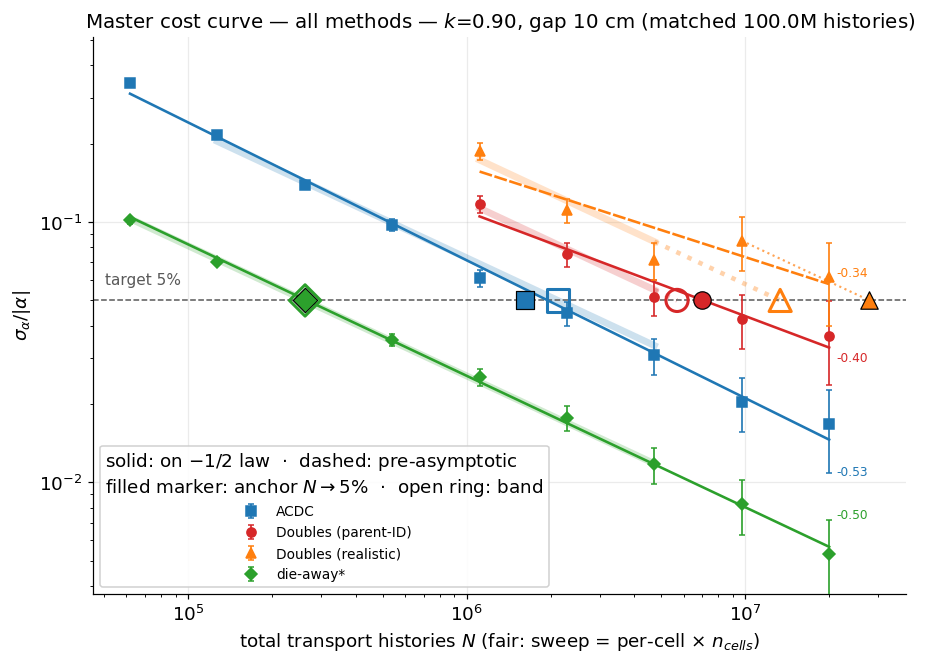

histories to sigma=5%|alpha| @ k=0.90 (band):
  ACDC: 2.1M  ·  Doubles (parent-ID): 5.7M  ·  Doubles (realistic): 13.3M  ·  die-away*: 262.6k
  -> Doubles (parent-ID) needs 2.7x ACDC's histories (the single-anchor rule read 4.3x, but with a 1-sigma bootstrap band of [2.3, 8.3] it could not tell those apart)


In [9]:
fig, ax = plt.subplots(figsize=(8.5, 6.2))
draw_master_curve(ax, curves, scaling, h2t, alpha_ref, band=band)
ax.set_title(f"Master cost curve — all methods — $k$={gl.K_OF_LABEL[FL]:.2f}, gap 10 cm "
             f"(matched {fmt_N(n_sphere)} histories)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "master_sigma_vs_N.png")
plt.show()

ann = "  ·  ".join(f"{M[m]['label']}: {fmt_N(band[m]['n_target'])}" for m in
                   ["acdc", "oracle", "realistic", "die"])
print("histories to sigma=5%|alpha| @ k=0.90 (band):\n ", ann)
if band["oracle"]["ok"] and band["acdc"]["ok"]:
    print(f"  -> Doubles (parent-ID) needs "
          f"{band['oracle']['n_target']/band['acdc']['n_target']:.1f}x ACDC's histories "
          f"(the single-anchor rule read "
          f"{h2t['oracle']['n_target']/h2t['acdc']['n_target']:.1f}x, but with a 1-sigma "
          f"bootstrap band of [2.3, 8.3] it could not tell those apart)")

### The headline: ACDC (eq 60) vs the analog Doubles (eq 59)

The figure above shows all four estimators, but two of them are not fair peers for the paper's
claim: **Doubles (parent-ID)** is an *oracle* (it uses the true chain labels to delete the
accidental background — no real experiment can), and **die-away** is a *singles*, pulsed-only
method. The comparison the paper's eq 59 vs 60 actually makes is **ACDC (the Green-function
method, eq 60, cost $\propto 1/\mu$) vs the realistic analog pair-counting (eq 59, cost
$\propto 1/\mu^2$)**. Stripped to those two, ACDC is the clear winner — cleaner *and* cheaper —
and the horizontal gap between the 5% markers is the measured efficiency ratio.

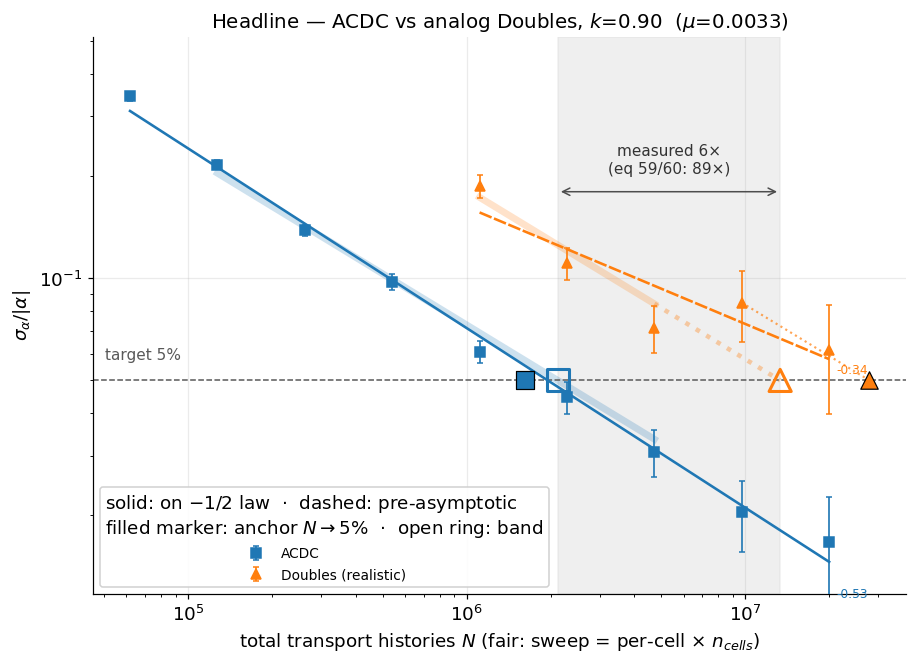

ACDC reaches 5% at 2.1M; analog Doubles at 13.3M  ->  6x (eq 59/60 predicts 89x; the single-anchor rule read 17x with a 1-sigma band of [9, 33])


In [10]:
mu_fl = rb.mu_detector(rb.FLAGSHIP_DOUBLES_TRACK, rb.FLAGSHIP_DOUBLES_DIR)["mu"]
ratio_pred = rb.eq5960_ratio(gl.K_OF_LABEL[FL], mu_fl, moment=rb.M_SIM)
# band estimator throughout (the anchor ratio, 17x here, carried a 1-sigma bootstrap
# band of [9, 33] and is quoted only for comparison). The realistic band keeps its
# health warning: 5 band points, the free slope furthest from -1/2, and the only
# method failing the split-vs-full consistency check.
ratio_meas = (band["realistic"]["n_target"] / band["acdc"]["n_target"]
              if (band["realistic"]["ok"] and band["acdc"]["ok"]) else np.nan)
ratio_anchor = (h2t["realistic"]["n_target"] / h2t["acdc"]["n_target"]
                if (h2t["realistic"]["ok"] and h2t["acdc"]["ok"]) else np.nan)

fig, ax = plt.subplots(figsize=(8.5, 6.2))
draw_master_curve(ax, curves, scaling, h2t, alpha_ref, methods=("acdc", "realistic"),
                  band=band)
# shade the histories gap between the two 5% targets
if np.isfinite(ratio_meas):
    Na, Nr = band["acdc"]["n_target"], band["realistic"]["n_target"]
    ax.axvspan(Na, Nr, color="0.85", alpha=0.4, zorder=0)
    # place the gap arrow + label in the empty band ABOVE the descending Doubles line
    # (which starts ~0.15 at the left edge of the gap) so they don't cross any curve.
    ax.annotate("", xy=(Nr, TARGET * 3.6), xytext=(Na, TARGET * 3.6),
                arrowprops=dict(arrowstyle="<->", color="0.3"))
    ax.text(np.sqrt(Na * Nr), TARGET * 4.0,
            f"measured {ratio_meas:.0f}×\n(eq 59/60: {ratio_pred:.0f}×)",
            ha="center", va="bottom", fontsize=10, color="0.2")
ax.set_title(f"Headline — ACDC vs analog Doubles, $k$={gl.K_OF_LABEL[FL]:.2f}  "
             f"($\\mu$={mu_fl:.2g})")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "master_acdc_vs_realistic.png")
plt.show()
print(f"ACDC reaches 5% at {fmt_N(band['acdc']['n_target'])}; analog Doubles at "
      f"{fmt_N(band['realistic']['n_target'])}  ->  {ratio_meas:.0f}x "
      f"(eq 59/60 predicts {ratio_pred:.0f}x; the single-anchor rule read "
      f"{ratio_anchor:.0f}x with a 1-sigma band of [9, 33])")

## 2b. What the master curve *is*: the paper's eq. 59 vs 60

This figure is the **empirical test of the paper's central efficiency claim** (Gabrieli et al.
2025, *Numerical Implications*). The paper estimates the emitted-neutron histories $N$ needed for
a relative uncertainty $E_r$ two ways:

$$\text{(57)}\quad \frac{\lambda_f}{\alpha}=\frac{1}{\bar\nu}\frac{k}{1-k}
\qquad\text{(fissions per source neutron)}$$
$$\text{(59, analog pair counting)}\quad N=\frac{2(1-k)\,\bar\nu^{3}}{k^{3}\,\mu^{2}\,\langle\nu(\nu-1)\rangle\,E_r^{2}}
\qquad\text{(60, Green-function product)}\quad N=\frac{2\bar\nu}{\mu\,E_r^{2}}$$

The analog method (eq 59, our **Doubles realistic** — it must resolve correlated pairs above the
accidental background) scales as $1/\mu^{2}$; the Green-function product method (eq 60, our
**ACDC**) scales as $1/\mu$. For a small detector efficiency $\mu$ this is a huge gap — the paper
quotes three orders of magnitude. The **vertical/horizontal separation between the ACDC and
Doubles-realistic curves above is that $1/\mu$ advantage**, measured directly:

$$\frac{N_{59}}{N_{60}}=\frac{(1-k)\,\bar\nu^{2}}{k^{3}\,\mu\,\langle\nu(\nu-1)\rangle}.$$

We measure $\mu$ from the flagship run and compare the predicted ratio to the measured
histories-to-target ratio.

In [11]:
mu = rb.mu_detector(rb.FLAGSHIP_DOUBLES_TRACK, rb.FLAGSHIP_DOUBLES_DIR)
k90 = gl.K_OF_LABEL[FL]
print(f"detector efficiency  mu = {mu['mu']:.3g}  (det/src={mu['det_per_src']:.3g}, "
      f"fiss/src={mu['fiss_per_src']:.2f})")
print(f"  eq-57 cross-check  fiss/src = (1/nubar) k/(1-k) = {(1/rb.NU_BAR)*k90/(1-k90):.2f}")

ratio_pred = rb.eq5960_ratio(k90, mu["mu"], moment=rb.M_SIM)   # simulated-world moment
ratio_meas = (band["realistic"]["n_target"] / band["acdc"]["n_target"]
              if band["realistic"]["ok"] and band["acdc"]["ok"] else np.nan)
print(f"\neq 59/60 PREDICTED ratio (analog / Greens) = {ratio_pred:.0f}x")
print(f"MEASURED N->5% ratio  (Doubles realistic / ACDC, band) = {ratio_meas:.0f}x")
print(f"  ACDC  N->5% = {fmt_N(band['acdc']['n_target'])}    "
      f"Doubles realistic N->5% = {fmt_N(band['realistic']['n_target'])}")

n_real = band["realistic"]["n_target"]
within = ("within" if (np.isfinite(n_real) and n_real <= n_sphere)
          else f"{n_real/n_sphere:.1f}x past" if np.isfinite(n_real) else "past")
print()
print("VERDICT: the master curve CONFIRMS the paper's qualitative claim -- the Green-function")
print("product method (ACDC) reaches a target precision with substantially fewer histories than")
print(f"analog pair counting ({ratio_meas:.0f}x measured here). The measured factor sits below the")
print(f"eq-59/60 estimate ({ratio_pred:.0f}x) because (a) our 'realistic' estimator is OPTIMIZED beyond")
print("the naive analog eq 59 (optimal source rate + MLE background subtraction), (b) eq 59/60 are")
print(f"order-of-magnitude estimates, and the Doubles-realistic N->5% ({fmt_N(n_real)}) is reached")
print(f"{within} the {fmt_N(n_sphere)} flagship data, and (c) the paper's two-detector product g1*g1")
print("differs from our single-detector autocorrelation by an O(1) factor.")

detector efficiency  mu = 0.00333  (det/src=0.00916, fiss/src=2.75)
  eq-57 cross-check  fiss/src = (1/nubar) k/(1-k) = 3.69

eq 59/60 PREDICTED ratio (analog / Greens) = 89x
MEASURED N->5% ratio  (Doubles realistic / ACDC, band) = 6x
  ACDC  N->5% = 2.1M    Doubles realistic N->5% = 13.3M

VERDICT: the master curve CONFIRMS the paper's qualitative claim -- the Green-function
product method (ACDC) reaches a target precision with substantially fewer histories than
analog pair counting (6x measured here). The measured factor sits below the
eq-59/60 estimate (89x) because (a) our 'realistic' estimator is OPTIMIZED beyond
the naive analog eq 59 (optimal source rate + MLE background subtraction), (b) eq 59/60 are
order-of-magnitude estimates, and the Doubles-realistic N->5% (13.3M) is reached
within the 100.0M flagship data, and (c) the paper's two-detector product g1*g1
differs from our single-detector autocorrelation by an O(1) factor.


### The same master curve at the near-critical edge ($k=0.98$)

Identical machinery, but at $k=0.98$ — where pairs are abundant (both
Doubles estimators measure at almost every plotted budget) and the slow near-critical decay
($1/|\alpha|\approx2.7$ ms) demands a long lag record. The ordering is read off the 5% markers and
the printout below. Two successive near-critical artifacts were found and fixed here, both
truncations of ACDC's lag support while the Doubles MLE used raw times: **(1)** an earlier
revision computed $R(\tau)$ on a 256-lag grid ending at 5 ms, halving the fit window (fixed by
sizing the lag range to the window); **(2)** the 10 ms per-cell histogram record itself truncated
the overlap integral $\int g_i(t)g_i(t+\tau)dt$ — a $1-e^{-2|\alpha|(T-\tau)}$ suppression reaching
~50% at $\tau=9$ ms — biasing $\alpha_{ACDC}$ to $-335$ vs PK's $-372$ and inflating ACDC's block
$\sigma$. Fixed 2026-07-12 by rebuilding $g_i(t)$ on a **40 ms record** from the raw events (no
new transport) and re-deriving the plateau window ($[1.37,\,9.51]$ ms): $\alpha_{ACDC}=-370.7$,
0.14$\sigma$ from PK. See `K098_EXTENSION_REPORT.md` for the acceptance gates (half-window check
3.68$\sigma\to$0.06$\sigma$).

Everything below runs through `project.analysis.flagship_k098`, which takes the record length, the
time grid, the fit window and the fission map from whichever dataset is on disk: the $k=0.98$
**flagship campaign** (`greens-sweep-k098-bench100M`, natively 40 ms, matched 100M sphere) when it
is available, and otherwise the bench10M 40 ms rebuild. The cell prints which one it used, and
every number in this section is from that dataset.

**Window and reference.** The fit window is derived from the dataset in use by the same plateau
rule, not carried over: on the 100M flagship that gives the **official $k=0.98$ window
$[1.5744,\,9.7717]$ ms** (against $[1.3655,\,9.5096]$ ms on the 10M record, a shift of 11 and 13 lag
bins), and the cost ladders use $\alpha_{ref}=-360.94$, the ACDC plug-in alpha on that window.
Both are printed below. The window choice is not what drives anything here: between the two windows
$\alpha_{ACDC}$ moves 0.28% and $\alpha_{BF}$ 0.37%, both under 1% of $\alpha$.

**Honest statement of the $k=0.98$ estimator agreement at 100M.** On the official window the two
estimators are $\alpha_{ACDC}=-360.9\pm1.7$ and $\alpha_{BF}=-369.2\pm1.2$, **3.9$\sigma$ apart**;
the absolute-scale gate reads $0.9874\pm0.0040$ on the matched fission map and the shape ratio
scale$/(M_{emp}/M_{sim})$ is $0.984\pm0.004$, $3.9\sigma$ from 1. Both say the same thing with the
same sign: the assembled ACDC curve decays about 2% too slowly and sits about 1.5% high. A
17-window scan puts $\alpha_{ACDC}$ above $\alpha_{BF}$ on every window tried, so this is not a
window artifact. The same-sign residual on the $k=0.90$ 100M flagship is $1.3\sigma$ on the alpha
pair and $0.7\sigma$ on the shape ratio, so it is a near-critical effect.

**And it is now diagnosed** (`GATE_DIAGNOSTICS_REPORT.md`, printed under the cell below). Put both
curves through identical baseline handling and the alpha gap is $0.5\%$ ($2\sigma$, $-364.8$ against
$-366.8$ s$^{-1}$ with each floor pinned at its own measured level): $1.7\%$ of the $2.2\%$ above is
the two fits choosing different flat baselines, at a leverage of $-474$ s$^{-1}$ per unit floor
fraction. The $1.5\%$ amplitude residual that survives is the in-record vs beyond-record split of
the pair weight ($55.09\%$ of the measured pairs at $\tau\le40$ ms against $55.95\%$ for the
assembly), not a transport or a statistics difference: the union of the 80 cell runs reproduces the
sphere run's pairs to $0.2\%$, and coarsening the assembly grid on the 1M $20\times20$ sweep drives
the shape ratio monotonically down (0.977, 0.973, 0.963, 0.949 for $20\times20$, $4\times5$,
$2\times5$, $1\times1$). So the residual is the within-cell weighting error of the assembly grid,
whose pair source $\propto F\,G^2$ sits deeper in a cell than the uniform cell average while deeper
birth points carry a larger delayed-branch share, and the zero-cost fix to test next is a
fission-weighted in-cell source for the confined runs. **The cost comparison
below is unaffected**: each method's $N\to5\%$ comes from its own $\sigma_\alpha(N)$ scaling, which
does not use the two estimators' agreement.

**Retraction of the previous $k=0.98$ headline.** This section used to report ACDC reaching 5% at
**104.8k histories** and a **8.2x** advantage over the parent-ID Doubles. Both rested on a single
ladder point: the single-anchor rule anchored on the 1.25M budget, which had only **7** convergent
blocks, and whose $\sigma$ came out a factor 3.1 below the $-1/2$ line through its neighbours, a
$P=0.004$ (1-in-270) downward fluctuation that the rule then squares. Sliding either neighbouring
budget alone gives 8.6e5 and 9.8e5, the 6-point band gives 1.03e6, and five independent 2M splits
give 1.03e6 $\pm$ 0.11e6, so the anchor was low by a factor of 10. On the band the ordering at
$k=0.98$ **reverses**: ACDC needs roughly 2.0 times *more* histories than the parent-ID Doubles
oracle here, not 8.2 times fewer. Full derivation in `COST_ESTIMATOR_REPORT.md` §5b. (That
derivation was made on the 10M record, where the band read 2.3 times and had to extrapolate 2.1x
past its top budget; on the 100M record every target sits inside its own band range, so nothing
extrapolates, and the factor settles at 2.0.)

k=0.98 DATASET IN USE: bench100M   sweep=greens-sweep-k098-bench100M.npz, record=40 ms (2048 bins), sweep 100,000,000 histories (1,250,000/cell x 80), sphere 99,999,970 histories


OFFICIAL k=0.98 WINDOW = [1.5744, 9.7717] ms  (plateau rule on this dataset; vetted extended-record window [1.3655, 9.5096])
alpha: ACDC -360.9 +/- 1.7   Doubles (parent-ID) -369.2 +/- 1.2   PK -371.6 +/- 4.9   ACDC vs Doubles: 3.86 sigma apart


gate  F=legacy    scale Doubles/ACDC = 0.9807   M_emp = 2.7495 +/- 0.0109   scale/(M_emp/M_SIM) = 0.9845 +/- 0.0040  (3.89 sigma from 1)
gate  F=matched   scale Doubles/ACDC = 0.9874   M_emp = 2.7681 +/- 0.0110   scale/(M_emp/M_SIM) = 0.9845 +/- 0.0040  (3.89 sigma from 1)
      1,556,245 Doubles pairs in the L>=3 mask, 1,625,007 detected chains
      the alpha pair and the shape ratio are the same ~2% residual seen twice, same sign; at k=0.90 (100M) the equivalents are 1.3 sigma and 0.7 sigma.
      DIAGNOSED (GATE_DIAGNOSTICS_REPORT.md): with identical baseline handling on both curves the alpha gap is 0.5% (2 sigma), i.e. 1.7% of the 2.2% above was the two fits choosing different flat baselines (leverage -474 s^-1 per unit floor fraction).
      The 1.5% amplitude residual is the in-record vs beyond-record split of the pair weight (55.09% of measured pairs at tau <= 40 ms vs 55.95% for the assembly): the union of the 80 cell runs reproduces the sphere pairs to 0.2%, and coarsening th

/home/itay/projects/initiation-project/project/analysis/rossi_benchmark.py:369: RuntimeWarning: overflow encountered in multiply
  return A + B * np.exp(np.clip(alpha * tau, -700, 700)) * corr


/home/itay/projects/initiation-project/project/analysis/rossi_benchmark.py:369: RuntimeWarning: overflow encountered in multiply
  return A + B * np.exp(np.clip(alpha * tau, -700, 700)) * corr


/home/itay/projects/initiation-project/project/analysis/rossi_benchmark.py:369: RuntimeWarning: overflow encountered in multiply
  return A + B * np.exp(np.clip(alpha * tau, -700, 700)) * corr


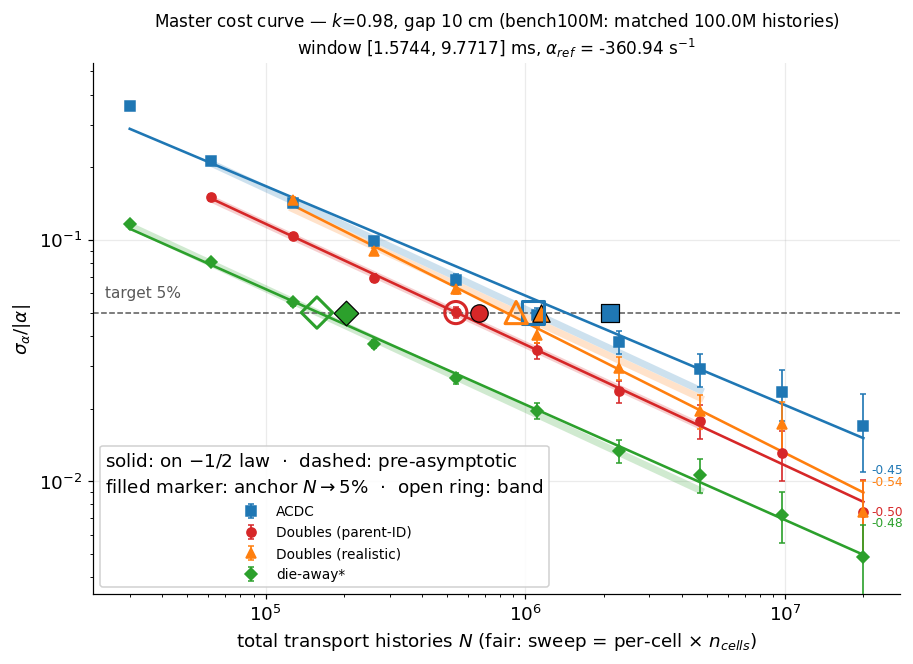

  Doubles (parent-ID): hidden (censored or sigma/|a|>=0.5) at N = 30.0k
  Doubles (realistic): hidden (censored or sigma/|a|>=0.5) at N = 30.0k, 61.8k

histories to sigma_alpha = 5%|alpha| @ k=0.98  [bench100M]

             method    band N  pts  stat %  rel_cap %  window %  quoted ± % splits  split mean  nσ split-vs-full  free slope  anchor N  anchor blk  anchor ± %  band/anchor
               ACDC 1.068e+06    7   2.917      1.082         0       3.111  10/10   1.054e+06            0.4555     -0.4972 2.113e+06          10       47.14       0.5055
Doubles (parent-ID)   5.4e+05    7   3.098     0.6324         0       3.162  10/10   5.224e+05              1.05     -0.5087 6.644e+05          10       47.14       0.8127
Doubles (realistic) 9.213e+05    6   3.864          0         0       3.864  10/10   1.006e+06             2.366     -0.5707 1.145e+06          10       47.14       0.8045
          die-away* 1.576e+05    8   2.123          0         0       2.123  10/10   1.571e+05      

In [12]:
# k=0.98 through project.analysis.flagship_k098: dataset selection, then the same
# audited estimators with the record length / time grid / window read from that
# dataset's own npz. Falls back to the bench10M 40 ms rebuild until the flagship
# campaign files land, and says which one it used.
FL98 = "098"
DS98 = fk98.resolve_dataset("bench100M", "bench10M")
inp98 = fk98.inputs(DS98)
print(f"k=0.98 DATASET IN USE: {DS98}   sweep={inp98['paths']['sweep_npz'].name}, "
      f"record={inp98['t_record']*1e3:.0f} ms ({inp98['n_t']} bins), "
      f"sweep {inp98['n_sweep_total']:,} histories "
      f"({inp98['n_cell']:,}/cell x {inp98['n_cells']}), "
      f"sphere {inp98['n_sphere']:,} histories")

w98d = fk98.window(DS98); win98 = w98d["window"]
a98 = fk98.alphas(DS98, win98, n_boot=200, rng=7)
print(f"OFFICIAL k=0.98 WINDOW = [{win98[0]*1e3:.4f}, {win98[1]*1e3:.4f}] ms  "
      f"(plateau rule on this dataset; vetted extended-record window "
      f"[{fk98.VETTED_EXT_WINDOW[0]*1e3:.4f}, {fk98.VETTED_EXT_WINDOW[1]*1e3:.4f}])")
print(f"alpha: ACDC {a98['acdc']:.1f} +/- {a98['acdc_sigma']:.1f}   "
      f"Doubles (parent-ID) {a98['bf']:.1f} +/- {a98['bf_sigma']:.1f}   "
      f"PK {a98['pk']:.1f} +/- {a98['pk_err']:.1f}   "
      f"ACDC vs Doubles: {a98['nsigma']:.2f} sigma apart")

# The absolute-scale gate on the SAME dataset and window: the honest companion to
# the alpha pair above. Both fission maps are reported; the matched map is this
# campaign's own tally and is the headline, the legacy 1M tally is the map the
# published gate used. shape_ratio = scale/(M_emp/M_SIM) is 1 when the assembled
# TIME STRUCTURE is right and the only residual is the pair moment.
g98 = fk98.gate(DS98, win98, n_boot=200, rng=7)
for which, v in g98["by_F"].items():
    print(f"gate  F={which:8s}  scale Doubles/ACDC = {v['scale']:.4f}   "
          f"M_emp = {v['M_emp']:.4f} +/- {v['M_err']:.4f}   "
          f"scale/(M_emp/M_SIM) = {v['shape_ratio']:.4f} +/- {v['shape_ratio_err']:.4f}  "
          f"({v['shape_nsigma']:.2f} sigma from 1)")
print(f"      {g98['n_pairs_mask']:,} Doubles pairs in the L>=3 mask, "
      f"{g98['n_chains_detected']:,} detected chains")
print("      the alpha pair and the shape ratio are the same ~2% residual seen twice, "
      "same sign; at k=0.90 (100M) the equivalents are 1.3 sigma and 0.7 sigma.")
print("      DIAGNOSED (GATE_DIAGNOSTICS_REPORT.md): with identical baseline handling on both "
      "curves the alpha gap is 0.5% (2 sigma), i.e. 1.7% of the 2.2% above was the two fits "
      "choosing different flat baselines (leverage -474 s^-1 per unit floor fraction).")
print("      The 1.5% amplitude residual is the in-record vs beyond-record split of the pair "
      "weight (55.09% of measured pairs at tau <= 40 ms vs 55.95% for the assembly): the union "
      "of the 80 cell runs reproduces the sphere pairs to 0.2%, and coarsening the assembly "
      "grid on the 1M 20x20 sweep drives the shape ratio down 0.977 / 0.973 / 0.963 / 0.949 "
      "for 20x20 / 4x5 / 2x5 / 1x1.")
print("      So it is the within-cell weighting error of the assembly grid (pair source ~ F G^2 "
      "sits deeper than the uniform cell average; deeper birth points carry a larger "
      "delayed-branch share); the zero-cost fix to test next is a fission-weighted in-cell "
      "source for the confined runs.")

# cost ladders + band + split-sample errors, one call (rb.cost_summary_flagship's
# recipe on this dataset; the ACDC block fn gets the dataset's own time grid).
# alpha_ref is the ACDC plug-in alpha on the official window above.
c98 = fk98.costs(DS98, win98, alpha_ref=a98["acdc"], verbose=False)
cur98, band98, h2t98, aref98 = c98["curves"], c98["band"], c98["anchor"], c98["alpha_ref"]
sca98 = {m: rb.fit_sigma_scaling(c, aref98) for m, c in cur98.items()}
summ98 = {c98["n_splits"]: c98["summary"].set_index("quantity")}
SPLIT_N98 = {m: c98["n_splits"] for m in cur98}
n_sph98 = inp98["n_sphere"]

fig, ax = plt.subplots(figsize=(8.5, 6.2))
draw_master_curve(ax, cur98, sca98, h2t98, aref98, band=band98)
ax.set_title(f"Master cost curve — $k$={gl.K_OF_LABEL[FL98]:.2f}, gap 10 cm "
             f"({DS98}: matched {fmt_N(n_sph98)} histories)\n"
             f"window [{win98[0]*1e3:.4f}, {win98[1]*1e3:.4f}] ms, "
             rf"$\alpha_{{ref}}$ = {aref98:.2f} s$^{{-1}}$", fontsize=11)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "master_sigma_vs_N_k098.png")
plt.show()

for m in cur98:
    hidden = cur98[m][cur98[m]["sigma"].isna()
                      | (cur98[m]["sigma"] / abs(aref98) >= REL_CAP)]["n_prime"].tolist()
    if hidden:
        print(f"  {M[m]['label']}: hidden (censored or sigma/|a|>={REL_CAP:g}) at N = "
              + ", ".join(fmt_N(n) for n in hidden))
# no fit-window systematic is measured at k=0.98 (its window spans ~420 lags, so a
# one-lag shift is 0.24% of the fit vs 1.9% at k=0.90); rel_cap is measured as at k=0.90
tab_cost98 = cost_table(cur98, band98, h2t98, summ98, SPLIT_N98, aref98, wsyst={})
print(f"\nhistories to sigma_alpha = 5%|alpha| @ k=0.98  [{DS98}]\n")
print(tab_cost98.to_string(index=False, float_format=lambda x: f"{x:,.4g}"))
if band98["oracle"]["ok"] and band98["acdc"]["ok"]:
    r98o = band98["oracle"]["n_target"] / band98["acdc"]["n_target"]
    r98o_anchor = h2t98["oracle"]["n_target"] / h2t98["acdc"]["n_target"]
    se = float(summ98[c98["n_splits"]].loc["ratio_oracle_acdc", "se_full"])
    print(f"\nN(Doubles parent-ID) / N(ACDC) = {r98o:.2f} +/- {se:.2f}  "
          f"({'ACDC' if r98o >= 1 else 'Doubles (parent-ID)'} cheaper here)")
    a_ns = float(summ98[c98["n_splits"]].loc["anchor_acdc", "n_sigma_vs_full"])
    print(f"RETRACTED: the single-anchor rule reads {r98o_anchor:.1f}x on the same "
          f"ladders (previously published as 8.2x with ACDC at 104.8k). Its ACDC anchor "
          f"sits on one thin ladder point whose sigma is a downward fluctuation, and its "
          f"own {c98['n_splits']}-split mean is {a_ns:.1f} sigma from its full-data value; "
          f"the band's is {float(summ98[c98['n_splits']].loc['n_target_acdc', 'n_sigma_vs_full']):.1f} sigma. "
          f"COST_ESTIMATOR_REPORT.md §5b.")

### Cross-check: is the across-realization $\sigma$ trustworthy?

The assumption-free across-realization std is the master curve's currency; the two cheap single-run
estimators are checked against it here (Doubles parent-ID, three flagship budgets, all three
estimators fitting at the same frozen $w_0$ so the comparison is like for like). The **MLE Fisher**
error should *track* the across-realization std; the **chain bootstrap** may run *optimistic*, but
if it does so by a **stable, measured factor** $\kappa_{boot}$ (printed below), that factor can be
calibrated out: wherever only a bootstrap $\sigma$ is affordable (the breadth Doubles costs in §3),
we multiply it by the measured $\kappa_{boot}$ to recover the across-realization standard. This
calibration — not a claim that bootstrap *equals* the across-realization std — is what licenses
sliding those costs along the $N^{-1/2}$ law.

In [13]:
checks = [rb.sigma_crosscheck(df10, int(n), n_sphere, win, n_boot=120, rng=7)
          for n in rb.budget_ladder(n_sphere)[[5, 6, 7]]]
xc = pd.DataFrame(checks)
xc["across/|a|"] = xc["across"] / abs(alpha_ref)
xc["boot/|a|"] = xc["boot"] / abs(alpha_ref)
xc["fisher/|a|"] = xc["fisher"] / abs(alpha_ref)
print("Doubles (parent-ID) sigma_alpha by estimator (relative to |alpha|):\n")
print(xc[["n_prime", "n_blocks_used", "across/|a|", "boot/|a|", "fisher/|a|"]]
      .to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# Calibration: chain-bootstrap sigma runs optimistic vs the gold-standard
# across-realization std by this measured factor. The breadth Doubles costs are
# bootstrap-based, so we scale their sigma up by kappa_boot to match the rigorous
# flagship. Measured at k=0.90; the Doubles method is only measurable at k=0.90-0.98,
# so this is interpolation within the band where it was measured.
KAPPA_BOOT = float((xc["across"] / xc["boot"]).mean())
print(f"\nbootstrap -> across-realization calibration  kappa_boot = {KAPPA_BOOT:.2f}")

Doubles (parent-ID) sigma_alpha by estimator (relative to |alpha|):

 n_prime  n_blocks_used  across/|a|  boot/|a|  fisher/|a|
 1111624             89      0.1174    0.1078      0.1044
 2289419             43      0.0751    0.0716      0.0725
 4715120             21      0.0516    0.0492      0.0504

bootstrap -> across-realization calibration  kappa_boot = 1.06


## 3. Cost of precision vs $k$ — where the Doubles method dies (INDICATIVE)

> **INDICATIVE, not a measurement of absolute cost.** Six of the eight $k$ have only a 1M budget,
> which is 40 to 100 times short of where the band estimator of §2 could interpolate, so every
> point here is a **single-point slide**: one $\sigma$ at one budget, slid down the $1/\sqrt N$ law
> (`rb.histories_for_sigma`). That is the same rule the retired single-anchor estimator used, and
> §2 measured what it costs: a single-budget $\sigma$ carries a large sampling error of its own, and
> low-budget $\sigma$ is biased high (pre-asymptotic), so the **absolute levels below carry an
> unquantified positive bias**. What the panel *does* support is everything that depends on the
> method being applied identically at every $k$: the shape of the cost-vs-$k$ trend, the relative
> ordering, and above all the **"no result" boundary** where the Doubles method never reaches 50
> window pairs. The two flagship $k$ (0.90, 0.98) are kept on the same single-point basis (their
> anchor read-off, the comparison column of §2's table) precisely so that all eight $k$ sit on one
> consistent basis; their band headline numbers are in §2 and §2c and differ.

For every $k$: histories (left) and wall-clock time (right) to reach $\sigma_\alpha=5\%|\alpha|$.
At the two $k$ that have a **flagship** run (0.90 and 0.98) the cost is read off the master-curve
anchor for all four methods (circled markers). At the other
six $k$ (no flagship) each method's best available $\sigma$ is slid down the $1/\sqrt{N}$ law
validated on the flagship: ACDC from the high-statistics sweep, the Doubles/die-away methods from
the 1M chain-bootstrap $\sigma$ — the Doubles $\sigma$ scaled up by the measured $\kappa_{boot}$
(§2) so bootstrap and across-realization agree. Where the Doubles method never reaches $\ge50$
window pairs it has **no result** (no marker — drawn, not asserted). Wall time uses each method's
*measured* per-history transport cost.

In [14]:
# INDICATIVE panel. Every point is a single-point slide down the 1/sqrt(N) law, so the
# two flagship k deliberately use their master-curve ANCHOR (h2t / h2t98), not the band
# headline of sections 2/2c, to keep one consistent method across all eight k. The
# absolute levels therefore carry the anchor's pre-asymptotic bias; the trend, the
# ordering and the "no result" boundary are what this panel supports.
# The other six k have no flagship, so slide each method's best 1M sigma down the
# 1/sqrt(N) law: ACDC from the high-stats sweep sigma (the bench-1M event-level sigma is noisy
# near critical); Doubles from the 1M chain-bootstrap sigma, scaled up by kappa_boot to
# the across-realization standard (nan where the 1M measurement was censored, <50 same-
# chain window pairs -- the "no result" boundary); die-away from its singles bootstrap.
# alpha_ref = high-stats ACDC consensus (the single denominator used everywhere).
FLAGSHIP_H2T = {rb.FLAGSHIP_LABEL: h2t, "098": h2t98}


def cost_for(r):
    L = r["label"]; a_ref = r["acdc_hi"]
    s_sp = rb.seconds_per_history_sphere(gl._fission_dir(L), 1e6)
    s_sw = rb.seconds_per_history_sweep(RESULTS / f"greens-sweep-k{L}-bench1M.npz")
    if L in FLAGSHIP_H2T:                       # flagship-measured, read off the curve
        H = FLAGSHIP_H2T[L]
        N = {m: (H[m]["n_target"] if H[m]["ok"] else np.nan)
             for m in ["acdc", "oracle", "realistic", "die"]}
        flagship = True
    else:                                       # 1/sqrt(N) slide of the best 1M sigma
        a_hi, s_hi, n_hi = acdc_best[L]
        N = {"acdc": rb.histories_for_sigma(s_hi, n_hi, a_ref, TARGET),
             "oracle": rb.histories_for_sigma(
                 np.nan if r["bf_oracle_cens"] else KAPPA_BOOT * r["bf_oracle_err"], 1e6, a_ref, TARGET),
             "realistic": rb.histories_for_sigma(
                 np.nan if r["bf_real_cens"] else KAPPA_BOOT * r["bf_real_err"], 1e6, a_ref, TARGET),
             "die": rb.histories_for_sigma(r["die_err"], 1e6, a_ref, TARGET)}
        flagship = False
    sph = {"acdc": s_sw, "oracle": s_sp, "realistic": s_sp, "die": s_sp}
    row = {"label": L, "k": r["k"], "flagship": flagship}
    for m, val in N.items():
        row[f"N_{m}"] = val
        row[f"T_{m}"] = val * sph[m] if np.isfinite(val) else np.nan
    return row


cost_k = pd.DataFrame([cost_for(r) for _, r in bench.iterrows()]).sort_values("k").reset_index(drop=True)
print(cost_k.to_string(index=False, float_format=lambda x: f"{x:.3g}"))

label     k  flagship   N_acdc  T_acdc  N_oracle  T_oracle  N_realistic  T_realistic    N_die  T_die
  040 0.402     False 6.44e+06      17       NaN       NaN          NaN          NaN 3.44e+05  0.869
  050 0.493     False 3.88e+06    12.8       NaN       NaN          NaN          NaN 3.66e+05   1.88
  060   0.6     False 3.51e+06    17.2       NaN       NaN          NaN          NaN 5.13e+05      5
  070 0.704     False 5.35e+06    39.1       NaN       NaN          NaN          NaN 3.78e+05   3.05
  080 0.806     False 3.64e+06    44.1       NaN       NaN          NaN          NaN 3.16e+05   5.36
  090 0.901      True 1.62e+06    45.8  6.99e+06       175     2.79e+07          699 2.63e+05    6.6
  095 0.951     False 1.64e+06     102  9.86e+05      61.7     4.58e+06          286 1.66e+05   10.4
  098  0.98      True 2.11e+06     262  6.64e+05      83.9     1.15e+06          145 2.05e+05   25.9


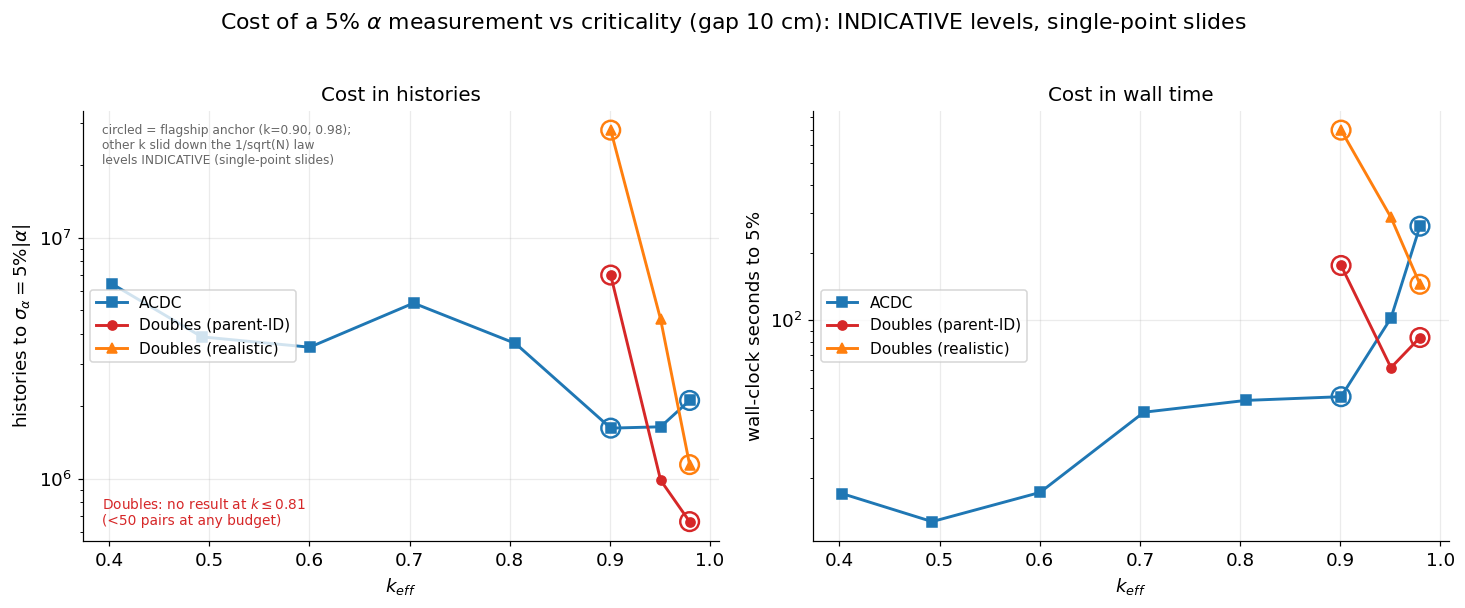

In [15]:
fig, (axN, axT) = plt.subplots(1, 2, figsize=(13.5, 5.4))
kk = cost_k["k"].to_numpy()
fl = cost_k["flagship"].to_numpy()
for m in ["acdc", "oracle", "realistic"]:
    meta = M[m]
    yN = cost_k[f"N_{m}"].to_numpy(); yT = cost_k[f"T_{m}"].to_numpy()
    keep = np.isfinite(yN)
    axN.plot(kk[keep], yN[keep], marker=meta["marker"], color=meta["color"], label=meta["label"])
    keepT = keep & np.isfinite(yT)
    axT.plot(kk[keepT], yT[keepT], marker=meta["marker"], color=meta["color"], label=meta["label"])
    # flagship-measured k (0.90, 0.98): big open rings = read straight off the master
    # curve; the realistic point censors out below k~0.85 (fix), so no REAL_CAP hack.
    axN.scatter(kk[keep & fl], yN[keep & fl], s=150, facecolor="none", edgecolor=meta["color"],
                linewidth=1.6, zorder=5)
    axT.scatter(kk[keepT & fl], yT[keepT & fl], s=150, facecolor="none", edgecolor=meta["color"],
                linewidth=1.6, zorder=5)
axN.text(0.03, 0.97, "circled = flagship anchor (k=0.90, 0.98);\nother k slid down the 1/sqrt(N) law\n"
         "levels INDICATIVE (single-point slides)",
         transform=axN.transAxes, fontsize=8, color="0.4", va="top")
for ax in (axN, axT):
    ax.set_yscale("log"); ax.set_xlabel(r"$k_{eff}$"); ax.legend(loc="center left")
axN.set_ylabel("histories to $\\sigma_\\alpha=5\\%|\\alpha|$")
axN.set_title("Cost in histories")
axT.set_ylabel("wall-clock seconds to 5%"); axT.set_title("Cost in wall time")
# annotate where the Doubles method has no result
no_o = cost_k[~np.isfinite(cost_k["N_oracle"])]["k"].tolist()
if no_o:
    axN.text(0.03, 0.03, f"Doubles: no result at $k\\leq${max(no_o):.2f}\n(<50 pairs at any budget)",
             transform=axN.transAxes, fontsize=9, color=M["oracle"]["color"], va="bottom")
fig.suptitle("Cost of a 5% $\\alpha$ measurement vs criticality (gap 10 cm): "
             "INDICATIVE levels, single-point slides", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cost_of_precision.png")
plt.show()

## 4. Why the Doubles method dies: pair starvation

The mechanism, made literal. The Doubles estimator needs same-chain detection *pairs*; the count
in the fit window scales as $\varepsilon^2\times$multiplication, so it collapses toward low $k$ and
with detector distance. Below the $\ge50$-pair floor (`MIN_PAIRS_FIT`) no fit is possible — the
shaded band is the "no result" region. (1M-history budget throughout.)

k=0.98 window pairs per 1M (extended window): 9266


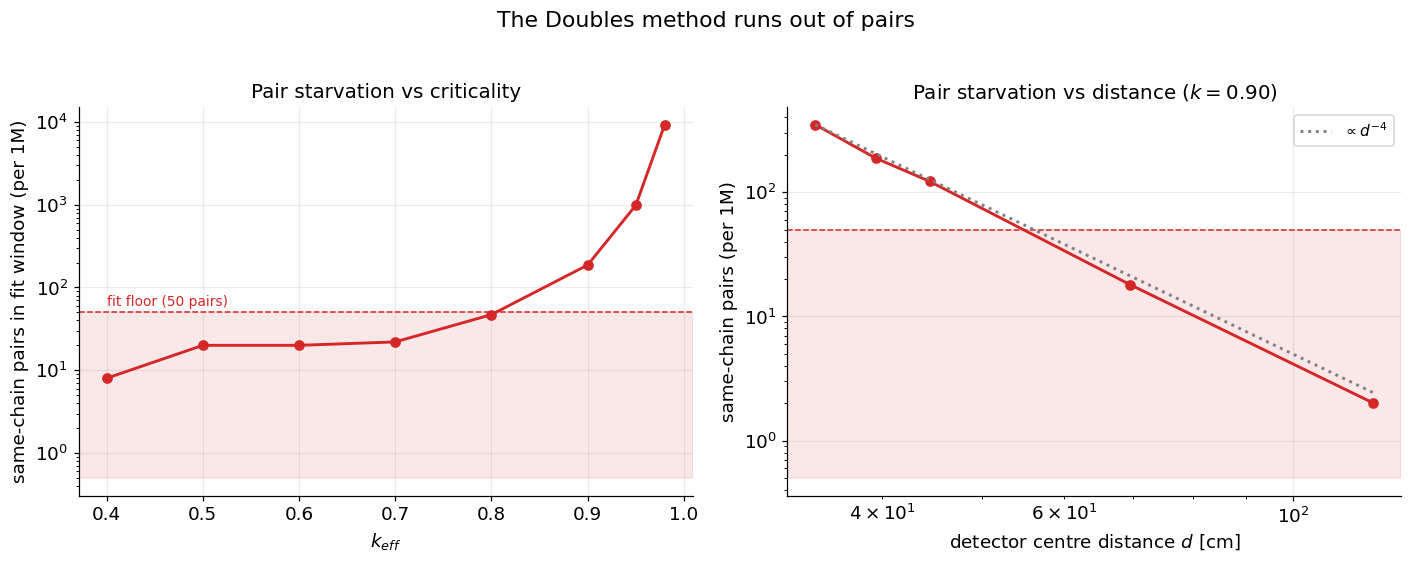

In [16]:
dck = rb.doubles_count_vs_k(LABELS)
# k=0.98's fit window moved with the record-extension fix (K098_EXTENSION_REPORT.md);
# recompute its in-window pair count on the extended window (supersedes the old 7350)
dck.loc[dck["label"] == "098", "pairs"] = kre.doubles_window_pairs_1M_ext()
print("k=0.98 window pairs per 1M (extended window):",
      int(dck.loc[dck['label'] == '098', 'pairs'].iloc[0]))
dcg = rb.doubles_count_vs_gap([5, 10, 15, 40, 90])
dcg = dcg[~dcg["missing"]].copy()
dcg["d"] = 24.5 + dcg["gap"] + 5.0   # detector centre distance [cm], k=0.90 (R=24.5)

fig, (axk, axd) = plt.subplots(1, 2, figsize=(13, 5))
axk.semilogy(dck["k"], dck["pairs"].clip(lower=0.5), "o-", color=M["oracle"]["color"])
axk.axhspan(0.5, rb.MIN_PAIRS_FIT, color=M["oracle"]["color"], alpha=0.10)
axk.axhline(rb.MIN_PAIRS_FIT, color=M["oracle"]["color"], ls="--", lw=1)
axk.text(dck["k"].min(), rb.MIN_PAIRS_FIT * 1.2, "fit floor (50 pairs)", fontsize=9,
         color=M["oracle"]["color"])
axk.set_xlabel(r"$k_{eff}$"); axk.set_ylabel("same-chain pairs in fit window (per 1M)")
axk.set_title("Pair starvation vs criticality")

axd.loglog(dcg["d"], dcg["pairs"].clip(lower=0.5), "o-", color=M["oracle"]["color"])
axd.axhspan(0.5, rb.MIN_PAIRS_FIT, color=M["oracle"]["color"], alpha=0.10)
axd.axhline(rb.MIN_PAIRS_FIT, color=M["oracle"]["color"], ls="--", lw=1)
dd = np.linspace(dcg["d"].min(), dcg["d"].max(), 40)
ref = dcg.iloc[0]
axd.loglog(dd, ref["pairs"] * (ref["d"] / dd) ** 4, ":", color="0.5", label=r"$\propto d^{-4}$")
axd.set_xlabel("detector centre distance $d$ [cm]"); axd.set_ylabel("same-chain pairs (per 1M)")
axd.set_title("Pair starvation vs distance ($k=0.90$)"); axd.legend()
fig.suptitle("The Doubles method runs out of pairs", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "why_doubles_dies.png")
plt.show()

## 5. Cost of precision vs detector distance ($k=0.90$) (INDICATIVE levels)

> **INDICATIVE, as in §3.** The gap-10 anchor propagated below is the single-anchor
> $N\to5\%$ (the comparison column of §2's table), not the band headline, and each gap has only a
> 10M run so no per-gap band is possible. Every gap is treated identically, so the **exponents are
> the result**: the Doubles cost rises as $d^4$ and ACDC's as $d^2$ because pairs die as
> $\varepsilon^2$ and singles as $\varepsilon$. The absolute levels inherit the anchor's bias
> (uniformly, so the two curves' *separation at fixed $d$* would move with the level but its
> *slope in $d$* would not).

The cleanest scaling result, built the honest way. A single 10M run per gap is too pair-sparse to
fit $\sigma$ independently at each distance (the cost-to-target then scatters wildly). But two
things *are* measured precisely: the **gap-10 cost from the flagship master curve**, and
the **detection counts at every gap** (the clean $\propto d^{-4}$ pairs / $\propto d^{-2}$ singles
from §4). With the validated $\sigma\propto N^{-1/2}$ law, cost $\propto 1/\text{counts}$, so we
anchor at gap 10 and propagate by the measured efficiency:

$$N_{Doubles}(d) = N_{Doubles}^{gap10}\,\frac{\text{pairs}(gap10)}{\text{pairs}(d)}\ (\propto d^4),
\qquad N_{ACDC}(d) = N_{ACDC}^{gap10}\,\frac{\text{singles}(gap10)}{\text{singles}(d)}\ (\propto d^2).$$

So the curves rest on three independently-validated pieces — the flagship anchor, the measured
counts, and the $1/\sqrt N$ law — not on noisy per-gap $\sigma$ fits.

In [17]:
GAPS = [5, 10, 15, 40, 90]
w90 = rb.FIT_WINDOWS["090"]

def _odir(g): return RESULTS / ("greens-function-k090-bench10M" if g == 10
                                else f"greens-function-k090-gap{g}-bench10M")
def _evp(g): return RESULTS / ("greens-sweep-k090-bench10M-events.h5" if g == 10
                               else f"greens-sweep-k090-gap{g}-bench10M-events.h5")

# measured detection efficiency at each gap (10M data)
pairs, singles, n_sph = {}, {}, {}
for g in GAPS:
    dfg = rb.load_chain_events_from(_odir(g) / "collision_track.h5")
    n_sph[g] = int(dfg["parent_id"].max())
    pairs[g] = rb.doubles_window_pairs(dfg, w90)
    evk, _ = rb.load_sweep_events(_evp(g))
    singles[g] = sum(len(t) for t, _ in evk.values())

# rigorous gap-10 anchors from the flagship master curve, propagated by efficiency
No0, Na0 = h2t["oracle"]["n_target"], h2t["acdc"]["n_target"]
s_sp = rb.seconds_per_history_sphere(_odir(10), n_sph[10])
s_sw = rb.seconds_per_history_sweep(RESULTS / "greens-sweep-k090-bench10M.npz")
rows = []
for g in GAPS:
    No = No0 * pairs[10] / pairs[g]
    Na = Na0 * singles[10] / singles[g]
    rows.append({"gap": g, "d": 24.5 + g + 5.0, "pairs": pairs[g], "singles": singles[g],
                 "N_oracle": No, "N_acdc": Na, "T_oracle": No * s_sp, "T_acdc": Na * s_sw})
cost_d = pd.DataFrame(rows)
print(cost_d.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

 gap     d  pairs  singles  N_oracle    N_acdc  T_oracle  T_acdc
   5  34.5   3312   125835 3.797e+06 1.183e+06     150.5    38.6
  10  39.5   1798    91780 6.994e+06 1.622e+06     277.2   52.92
  15  44.5   1117    70096 1.126e+07 2.124e+06     446.2   69.29
  40  69.5    147    27168 8.554e+07  5.48e+06      3391   178.8
  90 119.5     25     9011  5.03e+08 1.652e+07 1.994e+04     539


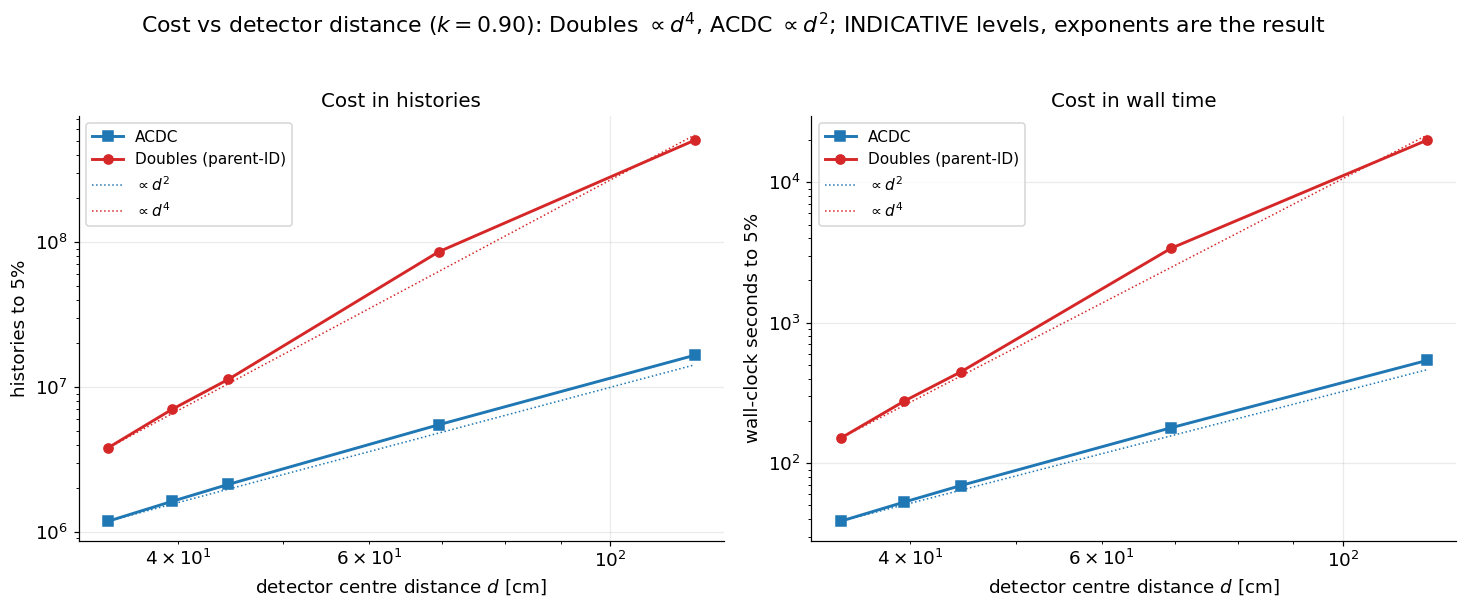

In [18]:
fig, (axN, axT) = plt.subplots(1, 2, figsize=(13.5, 5.4))
dd = np.linspace(cost_d["d"].min(), cost_d["d"].max(), 50)
for ax, col in [(axN, "N"), (axT, "T")]:
    for m in ["acdc", "oracle"]:
        meta = M[m]; y = cost_d[f"{col}_{m}"].to_numpy(); ok = np.isfinite(y)
        ax.loglog(cost_d["d"][ok], y[ok], marker=meta["marker"], color=meta["color"],
                  label=meta["label"])
    # scaling guides anchored at the nearest gap
    base = cost_d.dropna(subset=[f"{col}_acdc"]).iloc[0]
    ax.loglog(dd, base[f"{col}_acdc"] * (dd / base["d"]) ** 2, ":", color=M["acdc"]["color"],
              lw=1, label=r"$\propto d^2$")
    bo = cost_d.dropna(subset=[f"{col}_oracle"])
    if len(bo):
        b0 = bo.iloc[0]
        ax.loglog(dd, b0[f"{col}_oracle"] * (dd / b0["d"]) ** 4, ":", color=M["oracle"]["color"],
                  lw=1, label=r"$\propto d^4$")
    ax.set_xlabel("detector centre distance $d$ [cm]"); ax.legend()
axN.set_ylabel("histories to 5%"); axN.set_title("Cost in histories")
axT.set_ylabel("wall-clock seconds to 5%"); axT.set_title("Cost in wall time")
fig.suptitle("Cost vs detector distance ($k=0.90$): Doubles $\\propto d^4$, ACDC $\\propto d^2$; "
             "INDICATIVE levels, exponents are the result", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cost_vs_distance.png")
plt.show()

## 6. Efficiency ratio — "X times more expensive" (INDICATIVE, from §3/§5)

The single most intuitive view: the ratio of histories the **realistic** Doubles method (the
experiment-faithful analog estimator, the paper's eq 59) needs to ACDC's (eq 60), for equal
precision, vs $k$ and vs distance. Using realistic (not the chain-tagging *oracle*) keeps this
consistent with the eq-59/60 framing of §2b.

Both panels are built from §3 and §5, so they inherit their INDICATIVE status: the ratio is a
ratio of two single-point slides at every $k$ and every gap. The **distance** trend is the solid
part, because it is a pure geometry argument that every gap shares: pairs die as $\varepsilon^2$
and singles as $\varepsilon$, so the ratio grows as $d^2$ and ACDC's advantage widens without
bound as the detector moves away. The **$k$** trend is directional only. In particular, the
previous claim that the ratio "narrows toward critical but never crosses 1" is **withdrawn**: at
$k=0.98$ the band estimator (§2c) puts the parent-ID Doubles oracle *below* ACDC by a factor
$\approx2.0$ on the 100M flagship record, reversing the sign of the near-critical comparison that
the single-anchor rule reported. Whether the realistic (chain-blind) Doubles also crosses near critical is not settled by
this dataset: its band is the one method that fails the split-vs-full consistency check at both
$k$. Below $k\approx0.85$ the Doubles method simply has no result, and that boundary is robust:
it is a pair count, not an extrapolation. (The right panel's $d^2$ geometric scaling
uses the oracle, the only doubles estimator the single-run gap scans can fit; the realistic gap is
strictly *larger*.)

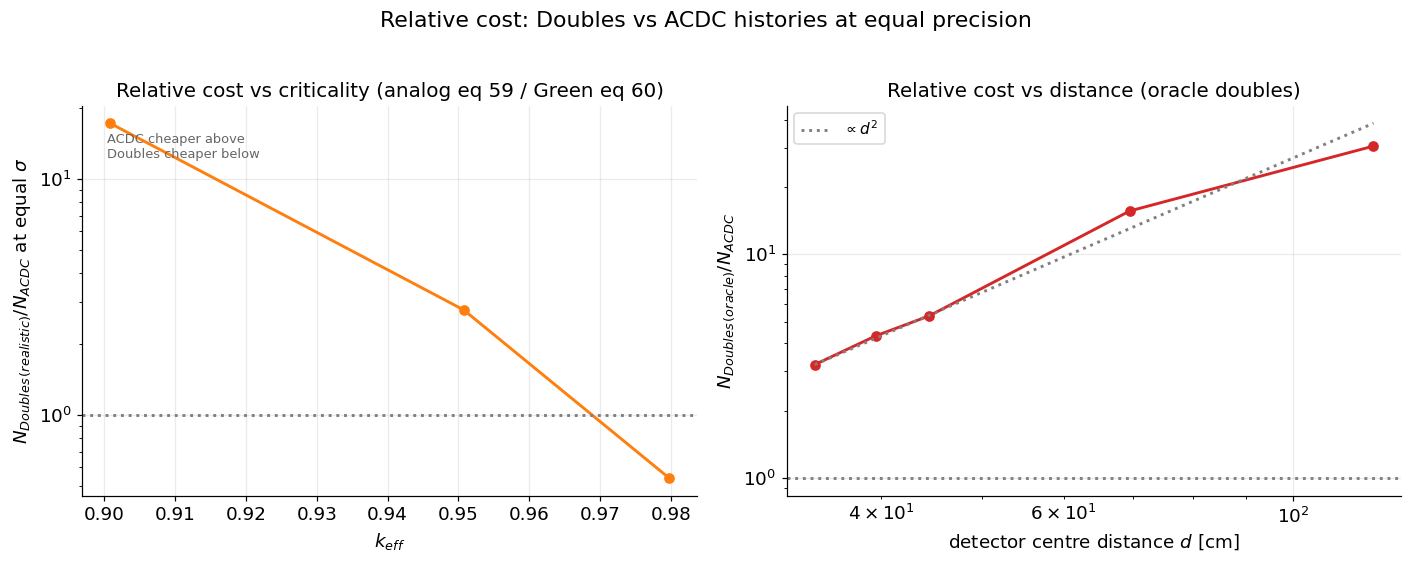

efficiency ratio N_Doubles(realistic)/N_ACDC by k: {'0.40': 'no result', '0.49': 'no result', '0.60': 'no result', '0.70': 'no result', '0.81': 'no result', '0.90': '17x', '0.95': '3x', '0.98': '0.54x'}


In [19]:
fig, (axk, axd) = plt.subplots(1, 2, figsize=(13, 5))
rk = cost_k["N_realistic"] / cost_k["N_acdc"]
ok = np.isfinite(rk)
axk.semilogy(cost_k["k"][ok], rk[ok], "o-", color=M["realistic"]["color"])
axk.axhline(1, color="0.5", ls=":")
axk.text(0.04, 0.93, "ACDC cheaper above\nDoubles cheaper below", transform=axk.transAxes,
         fontsize=8.5, color="0.4", va="top")
axk.set_xlabel(r"$k_{eff}$")
axk.set_ylabel(r"$N_{Doubles\,(realistic)}/N_{ACDC}$ at equal $\sigma$")
axk.set_title("Relative cost vs criticality (analog eq 59 / Green eq 60)")

rd = cost_d["N_oracle"] / cost_d["N_acdc"]
okd = np.isfinite(rd)
if okd.any():
    axd.loglog(cost_d["d"][okd], rd[okd], "o-", color=M["oracle"]["color"])
    dd = np.linspace(cost_d["d"].min(), cost_d["d"].max(), 40)
    base = cost_d[okd].iloc[0]
    axd.loglog(dd, rd[okd].iloc[0] * (dd / base["d"]) ** 2, ":", color="0.5", label=r"$\propto d^2$")
axd.axhline(1, color="0.5", ls=":")
axd.set_xlabel("detector centre distance $d$ [cm]")
axd.set_ylabel(r"$N_{Doubles\,(oracle)}/N_{ACDC}$")
axd.set_title("Relative cost vs distance (oracle doubles)")
if okd.any():
    axd.legend()
fig.suptitle("Relative cost: Doubles vs ACDC histories at equal precision", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "efficiency_ratio.png")
plt.show()

print("efficiency ratio N_Doubles(realistic)/N_ACDC by k:",
      {f"{k:.2f}": ("no result" if not np.isfinite(r)
                    else f"{r:.0f}x" if r >= 2 else f"{r:.2f}x")
       for k, r in zip(cost_k["k"], rk)})

## Conclusions

* **The methods agree on $\alpha(k)$; they differ enormously in cost.** That cost — not the value
  of $\alpha$ — is the result, and the master curve makes it legible: the same $\sigma$ sits at
  wildly different budgets for the Doubles method vs ACDC. (The exact histories-to-5%, efficiency
  ratios, and no-result boundary are printed in the summary cell below, straight from the in-memory
  results, so they cannot drift from the figures.)
* **ACDC is the cheaper pair-correlation estimator at the flagship $k=0.90$, and the advantage
  grows as the regime starves.** At $k=0.90$ the band puts the parent-ID Doubles oracle at 2.7
  times ACDC's histories and the realistic (chain-blind) Doubles higher still, and the gap widens
  toward deep subcriticality and with detector distance until the Doubles method stops measuring
  altogether. *In the starved regime*, deep subcritical or distant detector, ACDC is the **only**
  pair method left. (Pulsed die-away* is cheapest of all where it applies, but it is a singles
  method that needs a pulsable source.)
* **Near critical the ordering reverses, and the old claim that it never does is withdrawn.** At
  $k=0.98$ the band estimator puts ACDC at roughly 2.0 times the parent-ID Doubles oracle's
  histories, not 8.2 times fewer (§2c): the published 8.2x rested on one 7-block ladder point whose
  $\sigma$ was a 1-in-270 downward fluctuation. That is the expected direction, since near critical
  pairs are abundant and the Doubles method's $\varepsilon^2$ penalty is at its mildest. The
  statement that survives is about the *starved* regime, not about all $k$.
* **At $k=0.98$ and 100M the two estimators no longer agree to within their errors, and that is
  reported rather than smoothed over.** $\alpha_{ACDC}=-360.9\pm1.7$ against
  $\alpha_{BF}=-369.2\pm1.2$ is $3.9\sigma$, and the window-free shape ratio
  scale$/(M_{emp}/M_{sim})=0.984\pm0.004$ says the same thing with the same sign: the assembled
  curve decays about 2% too slowly. At $k=0.90$ and the same 100M budget the equivalents are
  $1.3\sigma$ and $0.7\sigma$, so it is a near-critical residual, not a global bias.
* **What that residual turned out to be** (`GATE_DIAGNOSTICS_REPORT.md`). Handle the baseline
  identically on both curves and the alpha gap is $0.5\%$ ($2\sigma$), so $1.7\%$ of the $2.2\%$
  above was the two fits choosing different flat baselines rather than the two curves disagreeing.
  The $1.5\%$ amplitude residual that remains lives entirely in the in-record vs beyond-record
  split of the pair weight ($55.09\%$ of the measured pairs at $\tau\le40$ ms against $55.95\%$ for
  the assembly), and it is not transport or statistics: the union of the 80 cell runs reproduces
  the sphere run's pairs to $0.2\%$, while coarsening the assembly grid on the 1M $20\times20$
  sweep drives the shape ratio monotonically down (0.977, 0.973, 0.963, 0.949 for $20\times20$,
  $4\times5$, $2\times5$, $1\times1$). It is therefore the within-cell weighting error of the
  assembly grid, whose pair source $\propto F\,G^2$ sits deeper in a cell than the uniform cell
  average while deeper birth points carry a larger delayed-branch share; the zero-cost fix to test
  next is a fission-weighted in-cell source for the confined runs, and the cost conclusions do not
  depend on any of it, because each method's $N\to5\%$ is fitted from its own $\sigma_\alpha(N)$.
* **The Doubles method literally has no result in the starved regimes** because the fit window
  never reaches 50 same-chain pairs (pairs $\propto\varepsilon^2\!\times$mult, dying as $\sim d^{-4}$
  with distance and collapsing at low $k$). We draw that boundary, we don't assert it.
* **ACDC degrades gracefully where the Doubles method dies:** singles scale as $\varepsilon$, so
  ACDC's cost grows only as $\sim d^2$ with distance while the Doubles pair tax grows as $\sim d^4$
  — ACDC survives to detector distances where doubles vanish entirely.
* **The `parent_id` oracle is an unphysical best case.** The realistic, chain-blind Doubles
  estimator costs more still (accidental background to fight), so any real doubles experiment is
  bounded *above* the red curve.
* **Wall time does not change the ordering:** the measured per-history transport costs of the
  sphere and sweep runs are comparable at the flagship $k$, so the wall-clock ranking tracks the
  histories ranking — it cannot manufacture pairs the detector never sees.
* **A small irony worth stating:** the Doubles method is so inefficient in the starved regime that
  even *characterizing* its inefficiency — measuring its $\sigma$ cleanly enough to extrapolate —
  needed the flagship deep-dive run. The pair scarcity that defeats the measurement also defeats
  the measurement *of* the measurement.

In [20]:
# Quantitative summary computed from the in-memory results (h2t, h2t98, cost_k), so it
# can never drift from the figures above. This is the permanent record of the numbers
# the static prose above deliberately leaves qualitative.
def _bound(lst):
    return f"k<={max(lst):.2f}" if lst else "none"

print("QUANTITATIVE SUMMARY (gap 10 cm)")
print("  HEADLINE numbers are the BAND estimator (§2, §2c); the anchor read-off is in "
      "brackets for comparison and is what §3/§5/§6 are built on.")
print(f"  flagship k=0.90  N->5% (band [anchor]):  " + "   ".join(
    f"{M[m]['label']}={fmt_N(band[m]['n_target'])} [{fmt_N(h2t[m]['n_target'])}]"
    for m in ["acdc", "oracle", "realistic", "die"]))
print(f"  flagship k=0.98 ({DS98})  N->5% (band [anchor]):  " + "   ".join(
    f"{M[m]['label']}={fmt_N(band98[m]['n_target'])} [{fmt_N(h2t98[m]['n_target'])}]"
    for m in ["acdc", "oracle", "realistic", "die"]))
if band["realistic"]["ok"] and band["acdc"]["ok"]:
    r90 = band["realistic"]["n_target"] / band["acdc"]["n_target"]
    print(f"  k=0.90: realistic Doubles / ACDC = {r90:.1f}x  ({'ACDC' if r90 >= 1 else 'Doubles'} cheaper)"
          f"   [health warning: the realistic band fails the split-vs-full check]")
if band["oracle"]["ok"] and band["acdc"]["ok"]:
    r90o = band["oracle"]["n_target"] / band["acdc"]["n_target"]
    print(f"  k=0.90: parent-ID Doubles / ACDC = {r90o:.1f}x  ({'ACDC' if r90o >= 1 else 'Doubles'} cheaper)")
if band98["oracle"]["ok"] and band98["acdc"]["ok"]:
    r98o = band98["oracle"]["n_target"] / band98["acdc"]["n_target"]
    print(f"  k=0.98: parent-ID Doubles / ACDC = {r98o:.2f}x  "
          f"({'Doubles' if r98o < 1 else 'ACDC'} cheaper)  <- REVERSES the retracted 8.2x")
print(f"  k=0.98 estimator agreement ({DS98}): alpha ACDC {a98['acdc']:.1f} +/- "
      f"{a98['acdc_sigma']:.1f} vs Doubles {a98['bf']:.1f} +/- {a98['bf_sigma']:.1f} "
      f"= {a98['nsigma']:.1f} sigma apart; shape ratio "
      f"{g98['by_F']['matched']['shape_ratio']:.3f} +/- "
      f"{g98['by_F']['matched']['shape_ratio_err']:.3f} "
      f"({g98['by_F']['matched']['shape_nsigma']:.1f} sigma from 1). Same-sign residual at "
      f"k=0.90 (100M) is 1.3 / 0.7 sigma.")
print("  k=0.98 residual, diagnosed (GATE_DIAGNOSTICS_REPORT.md): 1.7% of the 2.2% alpha gap "
      "was the two fits' different flat baselines (like-for-like gap 0.5%, 2 sigma); the "
      "1.5% amplitude residual is the in-record vs beyond-record pair-weight split (55.09% vs "
      "55.95% at tau <= 40 ms), i.e. the within-cell weighting error of the assembly grid "
      "(shape ratio 0.977 / 0.973 / 0.963 / 0.949 as the grid coarsens 20x20 -> 1x1). Fix to "
      "test next: a fission-weighted in-cell source for the confined runs.")
print("  efficiency ratio N_Doubles(realistic)/N_ACDC by k (INDICATIVE, §3 basis):")
rk_sum = cost_k["N_realistic"] / cost_k["N_acdc"]
for k, r in zip(cost_k["k"], rk_sum):
    tag = "no result" if not np.isfinite(r) else (f"{r:.0f}x" if r >= 2 else f"{r:.2f}x")
    print(f"      k={k:.2f}:  {tag}")
no_o = cost_k[~np.isfinite(cost_k["N_oracle"])]["k"].tolist()
no_r = cost_k[~np.isfinite(cost_k["N_realistic"])]["k"].tolist()
print(f"  Doubles 'no result' boundary: parent-ID {_bound(no_o)}, realistic {_bound(no_r)}")

QUANTITATIVE SUMMARY (gap 10 cm)
  HEADLINE numbers are the BAND estimator (§2, §2c); the anchor read-off is in brackets for comparison and is what §3/§5/§6 are built on.
  flagship k=0.90  N->5% (band [anchor]):  ACDC=2.1M [1.6M]   Doubles (parent-ID)=5.7M [7.0M]   Doubles (realistic)=13.3M [27.9M]   die-away*=262.6k [263.4k]
  flagship k=0.98 (bench100M)  N->5% (band [anchor]):  ACDC=1.1M [2.1M]   Doubles (parent-ID)=540.0k [664.4k]   Doubles (realistic)=921.3k [1.1M]   die-away*=157.6k [204.7k]
  k=0.90: realistic Doubles / ACDC = 6.3x  (ACDC cheaper)   [health warning: the realistic band fails the split-vs-full check]
  k=0.90: parent-ID Doubles / ACDC = 2.7x  (ACDC cheaper)
  k=0.98: parent-ID Doubles / ACDC = 0.51x  (Doubles cheaper)  <- REVERSES the retracted 8.2x
  k=0.98 estimator agreement (bench100M): alpha ACDC -360.9 +/- 1.7 vs Doubles -369.2 +/- 1.2 = 3.9 sigma apart; shape ratio 0.984 +/- 0.004 (3.9 sigma from 1). Same-sign residual at k=0.90 (100M) is 1.3 / 0.7 sigma.
 